# Generating images of British and Irish butterfly specimens with a deep convolutional GAN

**Patrick Gilliland**, AI Mastery Capstone: Generative AI Applications

This notebook trains a generative adversarial network (GAN) to make new 64 by 64 colour images of butterfly specimens, as the Natural History Museum (NHM) photographs them in its iCollections unit trays. `generative_model.ipynb` and `generative_ai.ipynb` are the same notebook under the two names the brief uses. The report ships as `Generative_AI_Analysis_Report.pdf` and, with the same content, as `module_summary.pdf`. The works cited here are listed in the report's References.

**Run notes.** The notebook trains on a graphics processing unit (GPU) when one is visible, and otherwise on the central processing unit (CPU).

| Item | This notebook |
|---|---|
| Rig | NVIDIA GeForce RTX 5090 graphics card, Intel Core Ultra 9 285K processor, Linux under Windows Subsystem for Linux (WSL2) |
| Python | 3.12.3 |
| PyTorch | 2.14.1 from the Python Package Index (PyPI) |
| CUDA | 13.0 (the runtime PyTorch ships with), cuDNN 9.24.0 |

The measured GPU training time and the estimated CPU training time, both from the last full run, are in Task 4's run-summary table.

## Task 1: Define the Generative Task and Select Your Approach

**Goal.** I train a generative model that makes new 64 by 64 colour images of British and Irish butterfly specimens, pinned and photographed as the Museum photographs them. The content it produces is images, generated from random noise. There is no prompt and no class label: the generator turns a vector of 100 random numbers into one image.

**Approach.** From the brief's list, "Generative Adversarial Network (GAN) for image generation". The model is an unconditional deep convolutional GAN (DCGAN) at 64 by 64 pixels, written and trained in this notebook with no pre-trained network. Task 3 explains each design choice.

**Data.**
- **Publisher.** The Natural History Museum, London, on its Data Portal (https://data.nhm.ac.uk), Specimens resource `05ff2255-c38a-40c9-b657-4ccb55ab2feb`.
- **Selection.** The iCollections British and Irish butterflies (Paterson et al., 2016): order Lepidoptera, project iCollections, the six butterfly families one query at a time, each record with one specimen photograph under Creative Commons Attribution 4.0 (CC BY 4.0). Records with more than one specimen photograph were left out, and Task 2's anomaly table counts them.
- **Licence.** CC BY 4.0, checked on each image's own licence field. I credit the Museum in the form it asks for. Its terms say it cannot warrant the data, and nothing here suggests that it endorses this work.
- **Size and download.** 22,000 photographs, one per specimen, downloaded on 13 October 2026 in a seed-2026 random order by `scripts/download_nhm_images.py`. That script runs once, outside this notebook. The fixed manifest, `data/manifest_fixed_20261013.csv`, lists every photograph with its SHA-256 hash, and the cell after the environment check prints the manifest's own hash.
- **How it is used.** `scripts/build_working_set.py` crops each photograph to the specimen, leaving out the ruler and the labels, and resizes it to 64 by 64. A seeded 10 per cent of the specimens is held out for evaluation only. All crops are used, in training and in the evaluation. The crop rule's automatic failure flag is reported in Task 2 as a finding about the data preparation, and never used to leave a crop out.

**The brief's dataset rules.**

| Rule (brief) | How this dataset meets it |
|---|---|
| Be appropriate for the chosen generative task | Thousands of photographs of one kind of object, taken to one protocol (Paterson et al., 2016, p. 4), which suits an image GAN |
| Be publicly available or clearly documented | Public on the NHM Data Portal under CC BY 4.0. The manifest and the download script document every photograph |
| Be appropriate for academic use | CC BY 4.0 allows reuse with attribution. The crop removes the labels, which carry collectors' handwriting and names, and the manifest keeps no field that names a person |
| Not be synthetic or AI-generated as a dataset | Photographs of real museum specimens |
| Not be reused from any previous capstone project | No earlier capstone project of mine used it. The prior-use search made before the dataset was chosen found none |

**How this could be used in the real world.** Three uses, strongest first. Each is my proposal, not something this notebook shows working.
1. **A quality flag for museum digitisation.** Museums photograph specimens in bulk and check the images afterwards. A European report on digitisation describes "the quality control activities that are performed after digitisation" (Nieva de la Hidalga et al., 2019, p. 4). The Museum and the Royal Botanic Garden Edinburgh describe a tool for "detecting missing objects (such as colour reference cards or barcodes), identifying cropping errors" on herbarium sheets (Zhang et al., 2026). In factory inspection, models learn from defect-free images alone, because "only a very limited amount of images with defects is available" (Bergmann et al., 2019, p. 2). My proposal: the trained discriminator has learned what a normal specimen photograph looks like, so it could score new photographs and pass the oddest to a person. Task 4 tests this once, on held-out photographs and known oddities.
2. **Images of rare species for identification tools.** Species photographs are uneven: "the natural world is heavily imbalanced, as some species are more abundant and easier to photograph than others" (Van Horn et al., 2018, p. 1). A GAN can be conditioned on a class label (Odena et al., 2017, p. 1). My proposal, as a next step: a conditional version of this GAN could add images of rare species to a training set. This notebook's GAN is unconditional and cannot choose a species.
3. **Material for spotting forged specimens.** The butterfly trade is regulated, and a guide for border officers notes that "Commercial shipments routinely use false declarations on import" (Environment Canada, 2000, p. 28). My proposal: generated fakes could help train people or tools to tell a real specimen photograph from a made one. No source I hold shows this done.

**Setup.** The first code cell sets two environment variables before PyTorch loads, seeds every random number generator and prints each seed. It fixes the settings that make a rerun repeat its numbers. When a GPU is visible, it prints the device, caps PyTorch at half the card's memory and prints how much of the 5090's memory is in use. That reading is for the record and never stops the notebook.

The cell also defines the training watchdog that Task 3 uses. It stops a run on a loss that is not a number, on an epoch over three times the median epoch before it, or on more than 20,000 MiB in use on the 5090. On this rig it also stops a run past 30 minutes. On any other machine that line only prints a warning, so a slower card still runs the notebook to the end.

In [1]:
import math
import os
import platform
import random
import statistics
import subprocess
import sys
import time
from pathlib import Path

# I pin the RTX 5090 (device 0) whatever the shell sets, because the rig's
# shell can show both its cards. The empty string is left alone: it hides
# every GPU for a CPU run. Deterministic cuBLAS needs its workspace set
# before torch loads.
if os.environ.get("CUDA_VISIBLE_DEVICES") != "":
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np  # noqa: E402
import torch  # noqa: E402

SEED_DATA = 2026  # the download order, the held-out split, the crop's 400
SEED_TRAIN = 42  # training, the fixed noise and 64 training images
SEED_SAMPLES = 7  # the 64 numbered samples and the held-out grid
random.seed(SEED_TRAIN)
np.random.seed(SEED_TRAIN)
torch.manual_seed(SEED_TRAIN)
torch.cuda.manual_seed_all(SEED_TRAIN)

# Deterministic cuDNN kernels, no autotuning and no TF32, so a rerun gives
# the same numbers and the arithmetic stays float32.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

GPU_NAME = "5090"
MEMORY_LINE_MIB = 20000
BUDGET_SECONDS = 1800.0


def smi_used_mib(text, name=GPU_NAME):
    """The memory in use, in MiB, on the first nvidia-smi row naming name.

    text is nvidia-smi's CSV output, with or without an index column and
    units. Returns None when no row names the card."""
    for line in text.splitlines():
        fields = [f.strip() for f in line.split(",")]
        for k, field in enumerate(fields[:-1]):
            if name in field:
                return int(fields[k + 1].split()[0])
    return None


def used_mib():
    """The 5090's memory in use, in MiB, or None with no GPU visible.

    Under WSL, torch.cuda.mem_get_info leaves out the Windows apps' share,
    so the reading is the larger of it and the card's nvidia-smi row, or
    mem_get_info alone where nvidia-smi is missing or has no 5090 row."""
    if not torch.cuda.is_available():
        return None
    free, total = torch.cuda.mem_get_info()
    readings = [(total - free) // 2**20]
    try:
        smi = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=name,memory.used",
                "--format=csv,noheader,nounits",
            ],
            capture_output=True,
            text=True,
            timeout=10,
            check=False,
        ).stdout
    except (OSError, subprocess.TimeoutExpired):
        smi = ""
    row = smi_used_mib(smi)
    if row is not None:
        readings.append(row)
    return max(readings)


def watchdog(
    loss,
    epoch_seconds,
    elapsed_seconds,
    used,
    on_rig,
    factor=3.0,
    budget_seconds=BUDGET_SECONDS,
    line_mib=MEMORY_LINE_MIB,
):
    """Why a training run should stop, and any warning, as (stop, warning).

    Either is None when it does not apply. A loss that is not finite stops
    a run anywhere. So does an epoch slower than factor times the median of
    the epochs before it, or used MiB above line_mib. A run past
    budget_seconds stops on the rig and only warns elsewhere, so a slower
    card still runs the notebook to the end. Every line is strict."""
    if not math.isfinite(loss):
        return f"the loss is {loss}", None
    if used is not None and used > line_mib:
        return f"the 5090 has {used} MiB in use, over {line_mib} MiB", None
    if len(epoch_seconds) > 1:
        line = factor * statistics.median(epoch_seconds[:-1])
        if epoch_seconds[-1] > line:
            return (
                f"the epoch took {epoch_seconds[-1]:.1f} s, over {line:.1f} s",
                None,
            )
    if elapsed_seconds > budget_seconds:
        minutes = f"{budget_seconds / 60:g} minutes"
        if on_rig:
            return f"the run passed {minutes}", None
        return None, f"the run passed {minutes}, so I carry on off the rig"
    return None, None


print(
    f"Python {platform.python_version()}, PyTorch {torch.__version__}, "
    f"NumPy {np.__version__}"
)
print(
    f"Seeds: data {SEED_DATA}, training {SEED_TRAIN}, samples {SEED_SAMPLES}"
)
print(
    f"CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']!r}, "
    f"CUBLAS_WORKSPACE_CONFIG={os.environ['CUBLAS_WORKSPACE_CONFIG']!r}"
)
on_gpu = torch.cuda.is_available()
if on_gpu:
    name = torch.cuda.get_device_name(0)
    on_rig = GPU_NAME in name
    cudnn = torch.backends.cudnn.version()
    print(
        f"Device: cuda, {name}, CUDA {torch.version.cuda}, "
        f"cuDNN {cudnn // 10000}.{cudnn % 10000 // 100}.{cudnn % 100}"
    )
    if not on_rig:
        print(f"Warning: not the RTX {GPU_NAME}, so the time line only warns")
    # Half the card at most, by this rig's GPU rules.
    torch.cuda.set_per_process_memory_fraction(0.5)
    print(f"GPU memory cap: half the card. In use on it now: {used_mib()} MiB")
else:
    on_rig = False
    print("Device: cpu, no GPU visible, so the time line only warns")

Python 3.12.3, PyTorch 2.14.1+cu130, NumPy 2.5.4
Seeds: data 2026, training 42, samples 7
CUDA_VISIBLE_DEVICES='0', CUBLAS_WORKSPACE_CONFIG=':4096:8'
Device: cuda, NVIDIA GeForce RTX 5090, CUDA 13.0, cuDNN 9.24.0
GPU memory cap: half the card. In use on it now: 5308 MiB


**Environment check.** The brief's own validation code, as given, reading this project's data file, the fixed manifest. In one cell only the last line's value is shown, so `device` on its own line prints nothing here. The setup cell above prints the device.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device
df = pd.read_csv("data/manifest_fixed_20261013.csv")
df.head()

,occurrence_id,catalog_number,family,genus,species,country,image_url,rendition,download_url,licence,file_name,sha256,bytes,width,height,download_utc
0,d3a4acf9-13dc-42bf-b13a-85e20cd62514,BMNH(E)1038104,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/b9470c19-d4cf-439...,original,https://data.nhm.ac.uk/media/b9470c19-d4cf-439...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038104_d3a4acf913dc42bfb13a85e20cd6251...,7cb05980550f9c5c321265dbcd93b33292f73df686da37...,139014,1440,960,2026-10-13T17:40:00Z
1,1403dc68-1fbf-4f26-964f-e0ece3da28b9,BMNH(E)1038105,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/06491a4b-f253-44c...,original,https://data.nhm.ac.uk/media/06491a4b-f253-44c...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038105_1403dc681fbf4f26964fe0ece3da28b...,327b36c56a9e9244638e02aa1029d48935e3a400f304e3...,148736,1440,960,2026-10-13T18:40:30Z
2,33dd91df-c8a1-4d83-99bc-a47f4b48c157,BMNH(E)1038110,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/420495a5-3c7b-46a...,original,https://data.nhm.ac.uk/media/420495a5-3c7b-46a...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038110_33dd91dfc8a14d8399bca47f4b48c15...,43b8685b9896fe9ff1dc43a2f5c6b9629cfb0a369dd3d0...,159091,1440,960,2026-10-13T16:43:35Z
3,2f9f0e9a-ba00-4988-a633-87453f980509,BMNH(E)1038115,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/897860cb-5b64-475...,original,https://data.nhm.ac.uk/media/897860cb-5b64-475...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038115_2f9f0e9aba004988a63387453f98050...,210337dad473e3fa75ed043e7dfdddccf88067291115c2...,310657,1440,2160,2026-10-13T17:44:18Z
4,0d630cab-f8b2-4df3-a3fc-adad35685fd5,BMNH(E)1038140,Nymphalidae,Aphantopus,hyperantus,Ireland,https://data.nhm.ac.uk/media/32e4f459-6944-405...,original,https://data.nhm.ac.uk/media/32e4f459-6944-405...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038140_0d630cabf8b24df3a3fcadad35685fd...,7cc16172ebfde0cde3b14506822fae181abf0c14d04415...,284676,1440,2160,2026-10-13T15:53:44Z


**The fixed set.** The next cell loads the crop rule and the split from the repository's `scripts/build_working_set.py`, then checks the manifest against the hash it was frozen with and prints when the photographs were downloaded.

In [3]:
# The crop rule, the flag and the split live in the repository's scripts
# folder, so the notebook and the array builder share one copy.
sys.path.insert(0, str(Path("scripts").resolve()))
import build_working_set as bws  # noqa: E402

MANIFEST = Path("data/manifest_fixed_20261013.csv")
MANIFEST_SHA256 = (
    "920fd9330771a12403a8cd07dea9b145dad633b7a86de81847b8a6c237cbbc80"
)
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
digest = bws.file_sha256(MANIFEST)
print(f"Fixed manifest: {MANIFEST}, {len(manifest):,} photographs")
print(f"SHA-256 {digest}, the frozen hash: {digest == MANIFEST_SHA256}")
print(
    f"Downloaded from {manifest['download_utc'].min()} to "
    f"{manifest['download_utc'].max()} (UTC), in a seed-{SEED_DATA} order"
)
print(
    f"Held out for evaluation: {bws.HELD_OUT_FRACTION * 100:.0f} per cent "
    f"of the specimens, seed {bws.SEED}"
)

Fixed manifest: data/manifest_fixed_20261013.csv, 22,000 photographs
SHA-256 920fd9330771a12403a8cd07dea9b145dad633b7a86de81847b8a6c237cbbc80, the frozen hash: True
Downloaded from 2026-10-13T14:59:57Z to 2026-10-13T19:00:32Z (UTC), in a seed-2026 order
Held out for evaluation: 10 per cent of the specimens, seed 2026


## Task 2: Load and Inspect Your Data or Prompt Source

**Goal.** Load the fixed manifest and the 64 by 64 working arrays, then show real photographs and their crops, and inspect the data's structure, formats and sizes before any model sees it. Every cell here reads only `data/`: the manifest, the photographs in `data/raw/`, and the arrays and row table that `scripts/build_working_set.py split` writes.

In [4]:
from IPython.display import display  # noqa: E402

STEM = "data/nhm_butterflies_64"
PARTS = ("training", "held_out", "flagged")
array_paths = {part: Path(f"{STEM}_{part}.npy") for part in PARTS}
rows_path = Path(f"{STEM}_rows.csv")
if not all(p.exists() for p in [*array_paths.values(), rows_path]):
    # Rebuilding crops and flags all 22,000 photographs: about three minutes
    # on this rig with 12 worker processes.
    started = time.perf_counter()
    status = bws.main(
        [
            "split",
            "--manifest",
            str(MANIFEST),
            "--raw-dir",
            "data/raw",
            "--out",
            STEM,
            "--workers",
            "8",
        ]
    )
    if status != 0:
        raise RuntimeError("the working arrays could not be built")
    print(f"Rebuilt the arrays in {time.perf_counter() - started:.0f} s")
arrays = {part: np.load(path) for part, path in array_paths.items()}
rows = pd.read_csv(rows_path, keep_default_na=False)
if list(rows["file_name"]) != list(manifest["file_name"]):
    raise ValueError("the row table is not in the manifest's order")
for part, path in array_paths.items():
    print(f"{path}: SHA-256 {bws.file_sha256(path)}")
print(f"{rows_path}: {len(rows):,} rows, one per manifest row")

data/nhm_butterflies_64_training.npy: SHA-256 4b697a5536b0329ac4b9972fa6bdfebfe898fdc5263bef3380734ab6f43bc131
data/nhm_butterflies_64_held_out.npy: SHA-256 dfbdb68e728444c3da975b2944df760e847d6c11ee2f087f2bd20700791ff568
data/nhm_butterflies_64_flagged.npy: SHA-256 b9ba67c14c869ef788dee3e334ae717a59d13c2c1d59574d53b3afde6e09315d
data/nhm_butterflies_64_rows.csv: 22,000 rows, one per manifest row


**The manifest.** One row per photograph: the specimen's identifiers and names, where it was collected, both download addresses, the licence, the file's name, hash, size in bytes and pixel size, and when it was downloaded. Nothing in it names a person. The tables count the photographs by family and by country.

In [5]:
def count_table(values, name):
    """Counts and per cent shares of values, largest first, as a new frame.

    A blank value is shown as "(blank)", so a missing country is counted
    and not dropped."""
    counts = values.replace("", "(blank)").value_counts()
    return pd.DataFrame(
        {
            name: counts.index,
            "images": counts.to_numpy(),
            "per cent": (100 * counts.to_numpy() / counts.sum()).round(1),
        }
    )


CC_BY = "http://creativecommons.org/licenses/by/4.0/"
print(f"Shape: {manifest.shape[0]:,} rows by {manifest.shape[1]} columns")
print(manifest.dtypes.to_string())
licensed = int((manifest["licence"] == CC_BY).sum())
print(f"Rows whose own licence field is CC BY 4.0: {licensed:,}")
print("Photographs by source rendition and pixel size:")
print(manifest.groupby(["rendition", "width", "height"]).size().to_string())
print(f"512-pixel renditions: {(manifest['rendition'] != 'original').sum()}")
display(count_table(manifest["family"], "family"))
display(count_table(manifest["country"], "country"))

Shape: 22,000 rows by 16 columns
occurrence_id       str
catalog_number      str
family              str
genus               str
species             str
country             str
image_url           str
rendition           str
download_url        str
licence             str
file_name           str
sha256              str
bytes             int64
width             int64
height            int64
download_utc        str
Rows whose own licence field is CC BY 4.0: 22,000
Photographs by source rendition and pixel size:
rendition                    width  height
full/!512,512/0/default.jpg  341    512         136
                             512    341          29
original                     1440   960        7292
                                    2160      14543
512-pixel renditions: 165


,family,images,per cent
0,Lycaenidae,9397,42.7
1,Nymphalidae,8520,38.7
2,Pieridae,2713,12.3
3,Hesperiidae,1056,4.8
4,Riodinidae,213,1.0
5,Papilionidae,101,0.5


,country,images,per cent
0,United Kingdom,18944,86.1
1,(blank),2064,9.4
2,Ireland,968,4.4
3,Isle of Man,24,0.1


**What the tables show.** Every row carries the CC BY 4.0 licence on its own image. Two families, Lycaenidae (the blues, coppers and hairstreaks) and Nymphalidae, make up most of the set, and Papilionidae, the swallowtails, are the fewest. Most photographs come from the United Kingdom, with Ireland and the Isle of Man after it, and some have no country, so I never call the set "UK only". Most photographs are 1,440 pixels wide, portrait or landscape, and a few are the Museum's 512-pixel rendition. The crop works in proportions of the photograph, so both sizes crop alike.

**Real photographs (Figure 1).** Six training photographs, drawn with seed 42 from those whose crop the flag passed. Each is shown whole, with the ruler, and with the label section beyond the crop painted grey, because the labels carry collectors' handwriting and names. I mask both the side where the rule found the labels and the side where a tray of that shape keeps them, in case the rule read the side wrongly. Their attribution lines follow, in the Museum's form; the manifest holds no update year, so it is given as n.d.

In [ ]:
def save_figure(fig, number, name, folder="outputs/figures"):
    """Save fig as figure_NN_name.png in folder, made if missing, and return
    its path."""
    path = Path(folder) / f"figure_{number:02d}_{name}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


def mask_label_side(rgb, box, side, grey=128):
    """A copy of rgb with everything past box on the label side made grey.

    box is (left, top, right, bottom) pixels and side is the label side the
    crop rule found, or None, when nothing is painted."""
    out = rgb.copy()
    left, top, right, bottom = box
    if side == "bottom":
        out[bottom:] = grey
    elif side == "top":
        out[:top] = grey
    elif side == "right":
        out[:, right:] = grey
    elif side == "left":
        out[:, :left] = grey
    return out


def label_sides(shape, side):
    """The sides to mask past the crop, as a list: the side the rule read,
    and the orientation's own label side, the bottom of a portrait tray or
    the right of a landscape one, in case the rule read it wrongly."""
    usual = "bottom" if shape[0] > shape[1] else "right"
    return [side, usual] if side not in (None, usual) else [usual]


def masked(photo, parts):
    """A copy of photo with every label side past the crop made grey."""
    out = photo
    for side in label_sides(photo.shape, parts["side"]):
        out = mask_label_side(out, parts["box"], side)
    return out


def attribution(row):
    """The Museum's attribution line for one manifest row, as a string.

    The title is the specimen's name and catalogue number, and the year is
    n.d., because the manifest keeps no update year."""
    name = " ".join(p for p in (row["genus"], row["species"]) if p)
    return (
        f"Natural History Museum. (n.d.). {name}, {row['catalog_number']} "
        "(from Collection specimens) [Photograph]. Natural History Museum. "
        "Licensed under CC-BY-4.0 "
        "(https://creativecommons.org/licenses/by/4.0). "
        f"https://data.nhm.ac.uk/object/{row['occurrence_id']}"
    )


passed = rows[(rows["part"] == "training") & (rows["flagged"] == 0)]
shown = passed.sample(6, random_state=SEED_TRAIN)["row"].to_list()
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
for ax, k in zip(axes.flat, shown):
    record = manifest.iloc[k]
    photo = bws.load_photograph(Path("data/raw") / record["file_name"])
    parts = bws.segment_parts(photo)
    ax.imshow(masked(photo, parts))
    ax.set_title(
        f"{record['genus']} {record['species']}\n{record['catalog_number']}",
        fontsize=9,
    )
    ax.axis("off")
fig.suptitle(
    "Figure 1. Six training photographs, label section masked in grey"
)
plt.tight_layout()
save_figure(fig, 1, "training_photographs")
plt.show()
for k in shown:
    print(attribution(manifest.iloc[k]))

**The crop rule and its failure flag (Figure 2).** The rule finds the ruler and the labels, marks what differs from the tray's grey, and boxes the specimen with a small margin. Each crop is padded to a square with the tray's colour and resized to 64 by 64 with Pillow's bilinear filter. Figure 2 shows the box in red on four more training photographs, their 64 by 64 crops, and 16 crops the flag marked.

Before any training I counted crop failures by eye on contact sheets: a failure is a crop where a wing, the body or a label crosses the box edge. The rule's own signals then give an automatic flag, set once on the 200 development images. It flags a crop when no specimen was found, when the specimen is under 5 or over 60 per cent of the tray, when marks cross more than a third of a side of the box, or when white paper lies along more than 5 per cent of a side. The eye counts and the flag's agreement with them are printed below the figure, with the totals the flag marks in the fixed set.

In [ ]:
def tile(images, cols, pad=2, fill=255):
    """The images laid out in rows of cols, with pad pixels of fill between
    them, as a new uint8 array."""
    n, h, w, c = images.shape
    rows_needed = math.ceil(n / cols)
    out = np.full(
        (
            rows_needed * h + (rows_needed - 1) * pad,
            cols * w + (cols - 1) * pad,
            c,
        ),
        fill,
        dtype=np.uint8,
    )
    for k in range(n):
        r, q = divmod(k, cols)
        y, x = r * (h + pad), q * (w + pad)
        bottom, right = y + h, x + w
        out[y:bottom, x:right] = images[k]
    return out


others = passed[~passed["row"].isin(shown)]
crop_rows = others.sample(4, random_state=SEED_TRAIN)
flag_draw = np.random.default_rng(SEED_TRAIN).choice(
    len(arrays["flagged"]), 16, replace=False
)
fig = plt.figure(figsize=(12, 12))
grid = fig.add_gridspec(3, 4, height_ratios=[3.2, 1.3, 1.9])
for col, (_, r) in enumerate(crop_rows.iterrows()):
    record = manifest.iloc[r["row"]]
    photo = bws.load_photograph(Path("data/raw") / record["file_name"])
    parts = bws.segment_parts(photo)
    left, top, right, bottom = parts["box"]
    ax = fig.add_subplot(grid[0, col])
    ax.imshow(masked(photo, parts))
    ax.add_patch(
        plt.Rectangle(
            (left, top),
            right - left,
            bottom - top,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
    )
    ax.set_title(f"{record['genus']} {record['species']}", fontsize=9)
    ax.axis("off")
    ax = fig.add_subplot(grid[1, col])
    ax.imshow(arrays["training"][int(r["array_row"])])
    ax.set_title("its 64 by 64 crop", fontsize=9)
    ax.axis("off")
ax = fig.add_subplot(grid[2, :])
ax.imshow(tile(arrays["flagged"][np.sort(flag_draw)], cols=8))
ax.set_title("16 crops the flag marked (seed 42), all still used", fontsize=9)
ax.axis("off")
fig.suptitle(
    "Figure 2. The crop rule's box on four training photographs, "
    "their crops, and flagged crops"
)
plt.tight_layout()
save_figure(fig, 2, "crop_rule")
plt.show()

# The eye count from the contact sheets, made before any training and kept
# outside this notebook, as (failures, images); then the flag against it as
# (caught, false alarms, missed, cleared), from the same sheets.
EYE_COUNT = {"development": (10, 200), "provisional": (24, 400)}
AGREEMENT = {"development": (9, 29, 1, 161), "provisional": (9, 62, 15, 314)}
for sample, (failed, seen) in EYE_COUNT.items():
    tp, fp, missed, tn = AGREEMENT[sample]
    print(
        f"{sample.capitalize()} sample: {failed} failures by eye of {seen} "
        f"({100 * failed / seen:.1f} per cent). Flag: {tp} caught, {fp} "
        f"false alarms, {missed} missed, {tn} cleared; precision "
        f"{tp / (tp + fp):.3f}, recall {tp / (tp + missed):.3f}"
    )
print(
    f"Flagged in the fixed set: {rows['flagged'].sum():,} of {len(rows):,} "
    f"({100 * rows['flagged'].mean():.1f} per cent), by reason:"
)
print(rows["flag_reasons"][rows["flagged"] == 1].value_counts().to_string())

**What the crop check shows.** By eye, the rule fails on about one crop in twenty. The flag catches most failures on the development images it was set on, but on the 400 provisional images it misses most of them and many of the crops it marks would pass by eye. Filtering by it would leave out about one photograph in five, most of them good, and still keep most of the failed crops. So I use all crops, and I report the flag as a finding about the data preparation: about one crop in twenty fails by eye, mostly at a label edge or a clipped wing, and Task 4 watches the samples for those artefacts. Most marked crops have marks across an edge of the box: a wing that runs to the edge, the platform's edge, or the top of a label.

**The working arrays (Figure 3).** The split stores the 64 by 64 RGB crops as uint8 arrays in manifest order: the training and held-out crops the flag passed, each part in its own array, and the crops it marked from both parts in a third. Task 3 rejoins them, so training uses every training crop and the evaluation every held-out crop. The cell prints the two parts' arrays' shape, type, size and pixel range, and Figure 3 shows 64 of the training crops the flag passed, drawn with seed 42.

In [ ]:
for part in ("training", "held_out"):
    a = arrays[part]
    print(
        f"{part}: shape {a.shape}, dtype {a.dtype}, "
        f"{a.nbytes / 2**20:.1f} MiB, pixel values {a.min()} to {a.max()}"
    )
train64 = np.sort(
    np.random.default_rng(SEED_TRAIN).choice(
        len(arrays["training"]), 64, replace=False
    )
)
plt.figure(figsize=(8, 8))
plt.imshow(tile(arrays["training"][train64], cols=8))
plt.title("Figure 3. 64 training images at 64 by 64 pixels (seed 42)")
plt.axis("off")
save_figure(plt.gcf(), 3, "training_crops")
plt.show()

**The held-out split.** A seeded 10 per cent of the specimens is held out: the first tenth of NumPy's `default_rng(2026)` permutation over the manifest's rows, which the manifest keeps sorted by file name. With one photograph per specimen, a split by photograph is a split by specimen. The cell prints each part's size with and without the flagged crops, then the families on each side and how often the flag marks each family and each rendition.

In [9]:
print(
    f"Seed {bws.SEED}: {bws.HELD_OUT_FRACTION * 100:.0f} per cent held out, "
    f"{bws.held_out_count(len(rows)):,} of {len(rows):,} specimens"
)
for part, label in (("training", "Training"), ("held_out", "Held out")):
    p = rows[rows["part"] == part]
    flagged = int(p["flagged"].sum())
    print(
        f"{label}: {len(p):,} photographs with the flagged crops, "
        f"{len(p) - flagged:,} without them ({flagged:,} flagged)"
    )
with_family = rows.assign(family=manifest["family"].to_numpy())
kept = with_family[with_family["flagged"] == 0]
families = (
    pd.DataFrame(
        {
            "training": with_family.loc[
                with_family["part"] == "training", "family"
            ].value_counts(),
            "training kept": kept.loc[
                kept["part"] == "training", "family"
            ].value_counts(),
            "held out": with_family.loc[
                with_family["part"] == "held_out", "family"
            ].value_counts(),
            "held out kept": kept.loc[
                kept["part"] == "held_out", "family"
            ].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
    .sort_values("training", ascending=False)
)
families["training per cent"] = (
    100 * families["training"] / families["training"].sum()
).round(1)
families["kept per cent"] = (
    100 * families["training kept"] / families["training kept"].sum()
).round(1)
families["flagged per cent"] = (
    100 * with_family.groupby("family")["flagged"].mean()
).round(1)
display(families)
by_rendition = (
    100 * rows.groupby(manifest["rendition"].to_numpy())["flagged"].mean()
).round(1)
print("Flagged per cent by rendition:")
print(by_rendition.to_string())

Seed 2026: 10 per cent held out, 2,200 of 22,000 specimens
Training: 19,800 photographs with the flagged crops, 16,000 without them (3,800 flagged)
Held out: 2,200 photographs with the flagged crops, 1,767 without them (433 flagged)


,training,training kept,held out,held out kept,training per cent,kept per cent,flagged per cent
family,,,,,,,
Lycaenidae,8453,6704,944,737,42.7,41.9,20.8
Nymphalidae,7672,6160,848,675,38.7,38.5,19.8
Pieridae,2459,2083,254,215,12.4,13.0,15.3
Hesperiidae,941,856,115,107,4.8,5.4,8.8
Riodinidae,181,142,32,29,0.9,0.9,19.7
Papilionidae,94,55,7,4,0.5,0.3,41.6


Flagged per cent by rendition:
full/!512,512/0/default.jpg    19.4
original                       19.2


**Preprocessing considerations.**
- **The crop is fixed.** It is set once, before training, and used for every run. It is a function of the photograph alone, with no learned part. Goodfellow et al. (2016, sec. 20.14, p. 714) warn that "changes in preprocessing, even very small and subtle ones, are completely unacceptable" when generative models are compared.
- **Square, then resize.** Each crop is padded to a square with the tray's own colour, so the specimen keeps its shape, then resized to 64 by 64 with Pillow's bilinear filter and stored as uint8.
- **Scaling for the generator.** Task 3 scales the pixels to the range -1 to 1, for the generator's Tanh output, on the GPU one batch at a time. Radford et al. (2016, sec. 4, p. 3) did the same: "No pre-processing was applied to training images besides scaling to the range of the tanh activation function [-1, 1]." Training adds one step of its own, a random horizontal flip of each image.
- **Two resolutions.** 165 photographs are the Museum's 512-pixel rendition. Every crop is shrunk far below that size, and the flag marks the renditions at about the same rate as the originals.
- **Flagged crops.** All crops are used. The flagged ones sit in their own array, and Task 3 rejoins them, so training uses all 19,800 training crops and the evaluation all 2,200 held-out crops. The flag is a finding, not a filter. It marks large specimens more often, the swallowtails most and the skippers least, so filtering by it would have shifted the family shares.
- **The held-out images.** They are read once, in Task 4, and never used to train the model or to choose a setting.

**The anomaly list.** Before any model sees the data, I list each kind of anomaly set out before the data was read, and three more that the data showed. Every row of the fixed set is kept and only marked. The table counts each kind in the fixed set, in each part, and among the rows the crop flag kept. Records the download skipped are counted from its own list of them, `data/candidates_skipped.csv`, when that file is on disk. The treatments follow the three options Van den Broeck et al. (2005, p. 968) give for a problem value: "The options are limited to correcting, deleting, or leaving unchanged."

In [ ]:
def anomaly_flags(manifest, rows):
    """A True or False column per kind of anomaly, one row per manifest row,
    as a new frame. Every row is kept and only marked.

    rows is the split's row table, which must be in the manifest's order."""
    if list(rows["file_name"]) != list(manifest["file_name"]):
        raise ValueError("the row table is not in the manifest's order")
    species = manifest["species"]
    return pd.DataFrame(
        {
            "file_name": manifest["file_name"].to_numpy(),
            "part": rows["part"].to_numpy(),
            "crop flagged": rows["flagged"].astype(bool).to_numpy(),
            "duplicate file": manifest["sha256"]
            .duplicated(keep=False)
            .to_numpy(),
            "duplicate occurrence": manifest["occurrence_id"]
            .duplicated(keep=False)
            .to_numpy(),
            "no country": (manifest["country"] == "").to_numpy(),
            "outside the UK": (
                ~manifest["country"].isin(["", "United Kingdom"])
            ).to_numpy(),
            "aberrant form named": species.str.contains(
                r"\bab\.|aberr", regex=True
            ).to_numpy(),
            "hybrid name": species.str.contains(" x ", regex=False).to_numpy(),
            "no species": (species == "").to_numpy(),
            "512-pixel rendition": (
                manifest["rendition"] != "original"
            ).to_numpy(),
        }
    )


def anomaly_counts(flags):
    """How many rows each kind of anomaly marks, as a new frame: in the
    fixed set, in each part, and among the rows the crop flag kept."""
    kept = ~flags["crop flagged"]
    out = []
    for kind in [c for c in flags.columns if c not in ("file_name", "part")]:
        marked = flags[kind]
        out.append(
            {
                "anomaly": kind,
                "fixed set": int(marked.sum()),
                "training": int(
                    (marked & (flags["part"] == "training")).sum()
                ),
                "held out": int(
                    (marked & (flags["part"] == "held_out")).sum()
                ),
                "not crop flagged": int((marked & kept).sum()),
            }
        )
    return pd.DataFrame(out)


TREATMENT = {
    "crop flagged": "kept and used; reported as a finding",
    "duplicate file": "none found",
    "duplicate occurrence": "none found",
    "no country": "kept and marked; the model never reads country",
    "outside the UK": "kept and marked; never called UK only",
    "aberrant form named": "no kept field names one; none marked",
    "hybrid name": "kept and marked; the model reads no names",
    "no species": "kept and marked; the model reads no names",
    "512-pixel rendition": "kept and marked; cropped in proportions",
}
skipped_path = Path("data/candidates_skipped.csv")
if skipped_path.exists():
    skipped = len(pd.read_csv(skipped_path))
    print(
        f"more than one specimen photograph: {skipped:,} records, skipped "
        "at download, so none is in the fixed set"
    )
else:
    print(
        "more than one specimen photograph: the download's list of skipped "
        "records is not on disk"
    )
flags = anomaly_flags(manifest, rows)
anomalies = anomaly_counts(flags)
anomalies["treatment"] = anomalies["anomaly"].map(TREATMENT)
with pd.option_context("display.max_colwidth", 60, "display.width", 160):
    display(anomalies)

**The treatments.** Nothing was corrected and no row was deleted. Every row of the fixed set stays in the row table, and every crop is used in training or in the evaluation. The crop-flagged ones are only stored in their own array. No file and no specimen appears twice. Records with a second specimen photograph never entered the fixed set, because the selection took one photograph per specimen. No kept field marks an aberrant form, though collectors sought them (Paterson et al., 2016, p. 12), so some may be in the photographs unmarked. Three kinds fall outside the categories set before the data was read: the hybrid name *Aricia agestis x artaxerxes*, records with a genus but no species, and the 512-pixel renditions. I keep all three, because an unconditional model reads no names and the crop works in proportions.

## Task 3: Implement and Train a Generative Model

**Design choices.** The model is an unconditional deep convolutional GAN (DCGAN) at 64 by 64 pixels, the pair of networks from my coursework DCGAN on the CelebA faces. Goodfellow et al. (2014, abstract, p. 1) train two models at once: "a generative model G that captures the data distribution, and a discriminative model D that estimates the probability that a sample came from the training data rather than G." Each choice below names its source and the output that shows how it played out.

- **Why a GAN.** The brief pairs a GAN with image generation. Goodfellow et al. (2016, sec. 20.10.3, p. 694) note that "samples from variational autoencoders trained on images tend to be somewhat blurry", and blur would hide the failure cases Task 4 has to name. The only peer-reviewed GAN study on museum specimen photographs I found, I could read only as a preprint, so the choice rests on the architecture papers.
- **Generator.** A noise vector of 100 numbers passes through five transposed convolutions, from 1 by 1 to 64 by 64 pixels, with 64 base channels. The first four are each followed by batch normalisation (BatchNorm) and a rectified linear unit (ReLU), and the last by Tanh. Radford et al. (2016, sec. 3, p. 3): "Use ReLU activation in generator for all layers except for the output, which uses Tanh." The network and its parameter count are printed below.
- **Discriminator.** Five strided convolutions take the image from 64 by 64 pixels to one value, with leaky ReLU (LeakyReLU) at slope 0.2, BatchNorm on all but the first layer, and a Sigmoid output. Radford et al. (2016, sec. 3, p. 3): "Replace any pooling layers with strided convolutions (discriminator) and fractional-strided convolutions (generator)." In sec. 4, p. 3: "In the LeakyReLU, the slope of the leak was set to 0.2 in all models."
- **Initialisation.** Convolution weights come from a normal distribution with mean 0 and standard deviation 0.02, BatchNorm weights from mean 1 and 0.02, and biases are 0. Radford et al. (2016, sec. 4, p. 3): "All weights were initialized from a zero-centered Normal distribution with standard deviation 0.02." Figure 4 shows what these weights make before training.
- **Loss.** Binary cross-entropy (BCE) on the Sigmoid outputs. The discriminator's loss is the sum of its real and generated terms, with real targets of 0.9 and generated targets of 0. Salimans et al. (2016, sec. 3.4, p. 4) "smooth only the positive labels to" a value below 1. The generator's target is 1, the non-saturating objective of Goodfellow et al. (2014, sec. 3, p. 3), which "provides much stronger gradients early in learning". The loss check below and Figure 5 show the losses against the random-guess line.
- **Optimiser.** Adam for each network at a learning rate of 0.0002, with betas (0.5, 0.999). Radford et al. (2016, sec. 4, pp. 3 to 4): "We found the suggested learning rate of 0.001, to be too high, using 0.0002 instead." and "reducing it to 0.5 helped stabilize training."
- **Batch and epochs.** Batches of 128 images, full batches only. Radford et al. (2016, sec. 4, p. 3): "All models were trained with mini-batch stochastic gradient descent (SGD) with a mini-batch size of 128." The 100 epochs are my assumption, not a source's. The checkpoints and the rule written below guard them.
- **Precision.** 32-bit floating point throughout, with TensorFloat-32 off and deterministic GPU kernels, so a rerun repeats its numbers. In my timing runs on this rig, bfloat16 was no faster, and my coursework notebook notes that "BCE + Sigmoid is sensitive to low-precision arithmetic".
- **EMA.** An exponential moving average (EMA) of the generator's weights, with decay 0.999, is updated after each generator step, with BatchNorm's running statistics copied across. It renders every sample, as my coursework DCGAN's did. No source I hold covers it, so it rests on the coursework alone. Figure 7 shows it at every checkpoint.
- **Data size.** Every one of the 19,800 training crops. Feng et al. (2021, Fig. 2 caption, p. 6704): "This results show that when the dataset size is small, GANs can generate almost exact replication of training data." Karras et al. (2020, p. 12104): "Training generative adversarial networks (GAN) using too little data typically leads to discriminator overfitting, causing training to diverge." The generator's 3.6 million parameters still far outnumber the training images, so Task 4's memorisation check is the evidence on copying.

**Where I leave my coursework DCGAN,** one line each, saying whether the difference is from its code or its saved run:
- Run 1 trains both networks at 0.0002, as the saved run did. The code now sets the discriminator to 0.00005, but no saved output shows that version, so run 1 adds only what the logged losses call for.
- Generated targets are 0, where both the code and the saved run used 0.1. Salimans et al. (2016, sec. 3.4, p. 3) explain why a non-zero target for generated samples harms the optimal discriminator: "The presence of pmodel in the numerator is problematic".
- The final model is the last epoch unless a written flag fires, where the code picked the epoch whose discriminator loss sat nearest 1.386. An untrained discriminator also sits near that line, and the saved run's pick was epoch 1.
- The generator's target is 1, where the code uses 0.9.
- No torchvision, where the code used it: Pillow and plain PyTorch crop, resize, flip and scale.
- The training set sits on the GPU as one uint8 tensor, where the code decoded the images every epoch. By my timing, decoding would make a run about 15 times slower.

**The training images.** Training uses every training crop, 19,800 in all: the 16,000 the crop flag kept and the 3,800 it marked, rejoined in the manifest's order. On the 400 crops scored by eye in Task 2, 62 of the 71 crops the flag marked had not failed, and it missed 15 of the 24 that had. Filtering by it would cost far more good crops than failed ones. About one crop in twenty fails by eye, mostly at a label edge or a clipped wing, so Task 4 watches the samples for those artefacts. The images go to the GPU once, as one uint8 tensor.

In [11]:
def part_images(arrays, rows, part):
    """Every crop in part, flagged or not, in the manifest's order, as a new
    uint8 array.

    rows is the split's row table. A crop the flag kept comes from the
    part's own array and a flagged one from the flagged array, each at the
    row the table gives it. A table out of step with the arrays raises
    ValueError."""
    p = rows[rows["part"] == part]
    kept = (p["flagged"] == 0).to_numpy()
    if kept.sum() != len(arrays[part]):
        raise ValueError(f"the row table and the {part} array disagree")
    out = np.empty((len(p), *arrays[part].shape[1:]), dtype=np.uint8)
    out[kept] = arrays[part][p.loc[kept, "array_row"].astype(int).to_numpy()]
    out[~kept] = arrays["flagged"][
        p.loc[~kept, "flagged_row"].astype(int).to_numpy()
    ]
    return out


training_images = part_images(arrays, rows, "training")
n_flagged = int(rows.loc[rows["part"] == "training", "flagged"].sum())
print(
    f"Training images: {len(training_images):,}, the "
    f"{len(arrays['training']):,} crops the flag kept and the "
    f"{n_flagged:,} it marked, in the manifest's order"
)
# One uint8 tensor on the device for the whole run, channels first. Each
# batch is scaled to -1 to 1 only when it is drawn.
train_u8 = (
    torch.from_numpy(training_images)
    .permute(0, 3, 1, 2)
    .contiguous()
    .to(device)
)
print(
    f"On {device}: shape {tuple(train_u8.shape)}, {train_u8.dtype}, "
    f"{train_u8.numel() / 2**20:.1f} MiB"
)
# The 64 training images drawn with seed 42 that the loss check, F4 and
# Task 4's colour measure read.
reference_index = np.sort(
    np.random.default_rng(SEED_TRAIN).choice(
        len(training_images), 64, replace=False
    )
)

Training images: 19,800, the 16,000 crops the flag kept and the 3,800 it marked, in the manifest's order
On cuda: shape (19800, 3, 64, 64), torch.uint8, 232.0 MiB


**The networks.** `Generator` and `Discriminator` follow the design above, and `make_models` builds a fresh pair from a seed with the initialisation above, leaving the global random state alone. The cell prints both networks layer by layer and counts their parameters. The counts are those of my coursework DCGAN.

In [12]:
import copy  # noqa: E402
import gc  # noqa: E402
import shutil  # noqa: E402

import torch.nn as nn  # noqa: E402
from torch.nn.utils.parametrizations import spectral_norm  # noqa: E402

NZ = 100  # the noise vector's length
NGF = 64  # the generator's base channel count
NDF = 64  # the discriminator's base channel count


class Generator(nn.Module):
    """The DCGAN generator: a noise vector to a 64 by 64 colour image."""

    def __init__(self, nz=100, ngf=64, nc=3):
        """Five transposed convolutions from 1 by 1 to 64 by 64 pixels, the
        first four followed by BatchNorm and ReLU, and Tanh on the last."""
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),  # 4 by 4
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),  # 8
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),  # 16
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),  # 32
            nn.BatchNorm2d(ngf),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),  # 64
            nn.Tanh(),
        )

    def forward(self, z):
        """Images in -1 to 1, shaped (batch, 3, 64, 64), for noise shaped
        (batch, nz, 1, 1)."""
        return self.main(z)


class Discriminator(nn.Module):
    """The DCGAN discriminator: a 64 by 64 colour image to the probability
    that it is a real photograph."""

    def __init__(self, nc=3, ndf=64):
        """Five strided convolutions from 64 by 64 pixels to one value, with
        LeakyReLU at slope 0.2, BatchNorm on all but the first, and a
        Sigmoid on the output."""
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),  # 32 by 32
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),  # 16
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),  # 8
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),  # 4
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),  # 1 by 1
            nn.Sigmoid(),
        )

    def forward(self, x):
        """One probability per image, shaped (batch,), for images in -1 to
        1 shaped (batch, 3, 64, 64)."""
        return self.main(x).view(-1)


def make_models(seed, spectral=False, nz=100, ngf=64, ndf=64):
    """A new generator and discriminator on the CPU, initialised from seed,
    as (generator, discriminator).

    Every convolution's weights are drawn from a normal distribution with
    mean 0 and standard deviation 0.02, and every BatchNorm weight from mean
    1 and 0.02, with its bias at 0. With spectral, every discriminator
    convolution is spectrally normalised. The global random state is left
    as it was."""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        generator, discriminator = Generator(nz, ngf), Discriminator(ndf=ndf)
        for net in (generator, discriminator):
            for m in net.modules():
                if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                    nn.init.normal_(m.weight, 0.0, 0.02)
                elif isinstance(m, nn.BatchNorm2d):
                    nn.init.normal_(m.weight, 1.0, 0.02)
                    nn.init.zeros_(m.bias)
        if spectral:
            for k, m in enumerate(discriminator.main):
                if isinstance(m, nn.Conv2d):
                    discriminator.main[k] = spectral_norm(m)
    return generator, discriminator


def count_parameters(model):
    """The number of trainable weights in model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


generator, discriminator = (
    net.to(device) for net in make_models(SEED_TRAIN, nz=NZ, ngf=NGF, ndf=NDF)
)
print(generator)
print(discriminator)
print(f"Generator: {count_parameters(generator):,} parameters")
print(f"Discriminator: {count_parameters(discriminator):,} parameters")

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding

**Before training (Figure 4).** One fixed batch of 64 noise vectors, drawn once with seed 42, is rendered here by the untrained generator and at every checkpoint by the EMA generator (Figure 7). Rendering runs in evaluation mode, so BatchNorm uses its running statistics. This is the baseline the trained samples are read against. Before training the generator gives a near-flat grey, with pixel values from 125 to 130. With BatchNorm on its starting statistics and weights this small, every output sits near the middle of Tanh's range.

In [ ]:
def noise_batch(n, seed, nz=100):
    """n noise vectors of length nz from a standard normal distribution,
    drawn by a CPU generator seeded with seed, as a new tensor shaped
    (n, nz, 1, 1), so every device starts from the same batch."""
    rng = torch.Generator().manual_seed(seed)
    return torch.randn(n, nz, 1, 1, generator=rng)


def render(model, z, device, chunk=256):
    """The images model makes from the noise z, as a new uint8 array shaped
    (n, 64, 64, 3).

    The model runs in evaluation mode, so BatchNorm uses its running
    statistics, under no_grad and chunk vectors at a time, then goes back
    to the mode it came in. Pixels from -1 to 1 map to 0 to 255."""
    was_training = model.training
    model.eval()
    out = []
    with torch.no_grad():
        for start in range(0, len(z), chunk):
            stop = start + chunk
            x = model(z[start:stop].to(device))
            x = ((x + 1) * 127.5).round().clamp(0, 255).to(torch.uint8)
            out.append(x.permute(0, 2, 3, 1).cpu())
    model.train(was_training)
    return torch.cat(out).numpy()


fixed_z = noise_batch(64, SEED_TRAIN, NZ)
before = render(generator, fixed_z, device)
plt.figure(figsize=(8, 8.4))
plt.imshow(tile(before, cols=8))
plt.title(
    "Figure 4. The untrained generator on the 64 fixed noise vectors "
    f"(seed {SEED_TRAIN})\nGenerated by a model, not a specimen"
)
plt.axis("off")
save_figure(plt.gcf(), 4, "before_training")
plt.show()
print(
    f"Pixel values {before.min()} to {before.max()}, mean {before.mean():.1f}"
)

**The loss convention.** The discriminator's loss is the sum of its two BCE terms, not their mean. So a discriminator that cannot tell real from generated, and gives 0.5 to every image, scores 2 ln 2 = 1.386, the random-guess line on Figure 5. Real targets of 0.9 leave that line where it is, because the BCE of an output of 0.5 is ln 2 against any target. The check scores the untrained discriminator on 64 training images and the 64 images of Figure 4, first in evaluation mode, then in training mode, as at the first training step. In evaluation mode the untrained discriminator gives 0.500 on both batches and the sum is 1.386, on the line. In training mode BatchNorm's batch statistics spread its outputs, and the sum moves to 1.467.

In [14]:
def summed_bce(
    discriminator, real, fake, real_target, fake_target, training=False
):
    """The discriminator's loss on one real and one generated batch, as a
    new dict: each BCE term, their sum, and mean D(x) and mean D(G(z)).

    A copy scores both batches under no_grad, in evaluation mode, or in
    training mode as at the first training step when training is True, so
    the discriminator passed in is unchanged."""
    probe = copy.deepcopy(discriminator).train(training)
    bce = nn.BCELoss()
    with torch.no_grad():
        on_real, on_fake = probe(real), probe(fake)
        real_term = bce(on_real, torch.full_like(on_real, real_target))
        fake_term = bce(on_fake, torch.full_like(on_fake, fake_target))
    return {
        "mean D(x)": on_real.mean().item(),
        "mean D(G(z))": on_fake.mean().item(),
        "real term": real_term.item(),
        "generated term": fake_term.item(),
        "sum": real_term.item() + fake_term.item(),
    }


def to_batch(images, device):
    """uint8 images shaped (n, 64, 64, 3) as a new float tensor on device,
    channels first and scaled to -1 to 1."""
    x = torch.from_numpy(images).permute(0, 3, 1, 2).to(device).float()
    return x / 127.5 - 1


real_64 = to_batch(training_images[reference_index], device)
fake_64 = to_batch(before, device)
print(
    "The untrained discriminator on the 64 training images (seed 42) and "
    "the 64 untrained samples of Figure 4, real targets 0.9 and generated "
    "targets 0:"
)
for mode, training in (("evaluation", False), ("training", True)):
    check = summed_bce(discriminator, real_64, fake_64, 0.9, 0.0, training)
    print(
        f"  in {mode} mode: mean D(x) {check['mean D(x)']:.4f}, mean D(G(z)) "
        f"{check['mean D(G(z))']:.4f}, real term {check['real term']:.4f}, "
        f"generated term {check['generated term']:.4f}, sum {check['sum']:.4f}"
    )
print(f"The random-guess line, 2 ln 2: {2 * math.log(2):.4f}")

The untrained discriminator on the 64 training images (seed 42) and the 64 untrained samples of Figure 4, real targets 0.9 and generated targets 0:
  in evaluation mode: mean D(x) 0.5004, mean D(G(z)) 0.5000, real term 0.6926, generated term 0.6931, sum 1.3857
  in training mode: mean D(x) 0.5466, mean D(G(z)) 0.4606, real term 0.7015, generated term 0.7651, sum 1.4666
The random-guess line, 2 ln 2: 1.3863


**Settings.** Every setting is fixed here, before any run, with its reason beside it. Runs 2 and 3 change only what the checkpoint rule below says.

In [15]:
hyper_rows = [
    ("batch", 128, "Radford et al. (2016, sec. 4); full batches only"),
    ("epochs", 100, "my assumption, guarded by the checkpoint rule"),
    ("lr_g", 0.0002, "Radford et al. (2016, sec. 4)"),
    ("lr_d", 0.0002, "the same rate for both networks in run 1"),
    ("betas", (0.5, 0.999), "Radford et al. (2016, sec. 4)"),
    ("real_target", 0.9, "one-sided smoothing (Salimans et al., 2016)"),
    ("fake_target", 0.0, "unsmoothed, so the smoothing is one-sided"),
    ("gen_target", 1.0, "the non-saturating loss (Goodfellow et al., 2014)"),
    ("ema_decay", 0.999, "the EMA generator of my coursework DCGAN"),
    ("seed", SEED_TRAIN, "weights, batch order, flips and noise"),
]
CHECKPOINTS = (0, 1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100)
# Run 3's discriminator rate under TTUR, the rate my coursework code sets.
LR_D_TTUR = 0.00005
RUN1 = {name: value for name, value, _ in hyper_rows}
RUN1.update(
    run=1, nz=NZ, spectral=False, checkpoints=CHECKPOINTS, max_steps=None
)
print(
    pd.DataFrame(
        hyper_rows, columns=["setting", "value", "why"], dtype=object
    ).to_string(index=False)
)
steps = len(training_images) // RUN1["batch"]
print(
    f"\n{steps} full batches of {RUN1['batch']} an epoch, leaving "
    f"{len(training_images) - steps * RUN1['batch']} images out of each "
    f"epoch's shuffle, so {steps * RUN1['epochs']:,} generator updates in "
    f"{RUN1['epochs']} epochs"
)
print(f"Checkpoints at epochs {', '.join(map(str, CHECKPOINTS))}")

    setting        value                                               why
      batch          128  Radford et al. (2016, sec. 4); full batches only
     epochs          100     my assumption, guarded by the checkpoint rule
       lr_g       0.0002                     Radford et al. (2016, sec. 4)
       lr_d       0.0002          the same rate for both networks in run 1
      betas (0.5, 0.999)                     Radford et al. (2016, sec. 4)
real_target          0.9       one-sided smoothing (Salimans et al., 2016)
fake_target          0.0         unsmoothed, so the smoothing is one-sided
 gen_target          1.0 the non-saturating loss (Goodfellow et al., 2014)
  ema_decay        0.999          the EMA generator of my coursework DCGAN
       seed           42             weights, batch order, flips and noise

154 full batches of 128 an epoch, leaving 88 images out of each epoch's shuffle, so 15,400 generator updates in 100 epochs
Checkpoints at epochs 0, 1, 5, 10, 20, 30, 40, 50, 

**The checkpoint rule, written before training.** A GAN has no validation loss, so a rule fixed now chooses the final model. Salimans et al. (2016, sec. 4, p. 4): "Generative adversarial networks lack an objective function, which makes it difficult to compare performance of different models." **The final model is the EMA generator at the last epoch, unless a failure flag fires.** The flags read training-side quantities only, never a held-out image.

| Flag | Name | Fires when |
|---|---|---|
| F1 | Discriminator domination | The epoch-mean discriminator loss is below 0.425, its floor plus 0.10, for 5 epochs in a row |
| F2 | Discriminator failure | The epoch-mean discriminator loss is above 1.5 for 5 epochs in a row, after epoch 5 |
| F3 | Unstable generator | From epoch 10 on, the standard deviation of the per-batch generator loss over the last 10 epochs is above 1.0 |
| F4 | Mode collapse | At a checkpoint from epoch 10 on, the mean pairwise Euclidean distance among the 64 fixed-noise images is below 0.5 times the same measure on the 64 training images drawn with seed 42 |
| F5 | Non-finite loss | Any loss is not a finite number, which also stops the run |

- **Grounds.** With generated targets of 0, the summed loss cannot fall below the BCE of a real target of 0.9 against itself, 0.325, so F1's line follows the loss convention. F1, F2 and F3 take their thresholds from the checks in my coursework GAN exercise, which read the last third of training. Their epoch windows and F4's 0.5 are my assumptions. Karras et al. (2020, p. 12104) find that with too little data the discriminator overfits and training diverges. Radford et al. (2016, sec. 7, p. 9), on F3: "we noticed as models are trained longer they sometimes collapse a subset of filters to a single oscillating mode." Heusel et al. (2017, sec. 2, p. 4), on F4, describe collapse as when "only few prototype samples are generated".
- **Fallback.** If a flag fires, the final model is the EMA generator at the last checkpoint from epoch 5 on before that flag's window began. If there is none, the run has failed. If several flags fire, the earliest window decides. Every line is strict, so a value on it does not fire.
- **Runs 2 and 3.** F1, F3, F4 or F5 in run 1 call run 2, which adds spectral normalisation to every discriminator convolution. Miyato et al. (2018, abstract, p. 1): "we propose a novel weight normalization technique called spectral normalization to stabilize the training of the discriminator." The same flags in run 2 call run 3, which keeps it and lowers the discriminator's learning rate to 0.00005 against the generator's 0.0002, the two time-scale update rule (TTUR). Heusel et al. (2017, abstract, p. 1): "TTUR has an individual learning rate for both the discriminator and the generator." There is no fourth run, and the final model comes from the last run made.
- **F2 calls no run.** The discriminator is losing, and both fixes restrain it further, so the notebook reports the failure and keeps that run's fallback model.
- **Watchdog stops.** A stop for memory, the 30-minute budget or a slow epoch is not a training failure. It stops the notebook, with no further run.

In [ ]:
def mean_pairwise_distance(images):
    """The mean Euclidean distance over every pair of images, each
    flattened, as a float. Fewer than two images raise ValueError."""
    if len(images) < 2:
        raise ValueError("a pairwise distance needs two images or more")
    x = np.asarray(images, dtype=np.float64).reshape(len(images), -1)
    squares = (x * x).sum(axis=1)
    d2 = squares[:, None] + squares[None, :] - 2 * (x @ x.T)
    upper = np.triu_indices(len(x), k=1)
    return float(np.sqrt(np.maximum(d2[upper], 0)).mean())


def run_of(held, length, start=1):
    """The first epoch that ends length epochs in a row on which held is
    True, counting from epoch start, with the epoch that run began, as
    (epoch, first epoch), or None. held[k] is for epoch k + 1."""
    count = 0
    for epoch, holds in enumerate(held, 1):
        count = count + 1 if (holds and epoch >= start) else 0
        if count == length:
            return epoch, epoch - length + 1
    return None


def read_flags(
    log,
    ratios,
    nonfinite_epoch,
    lines,
    length=5,
    after=5,
    window=10,
    first_checkpoint=10,
    first_epoch=1,
):
    """Each failure flag's first firing as (epoch, first epoch of its
    window), or None, in a new dict keyed F1 to F5.

    log is shaped (epochs, batches, 4): the summed discriminator loss, the
    generator loss, mean D(x) and mean D(G(z)) of every batch. ratios maps
    each checkpoint epoch to its fixed-noise diversity ratio. Every line is
    strict, so a value on a line does not fire. No window takes in an epoch
    before first_epoch, which is epoch 1 in the rule as written."""
    d_means = log[:, :, 0].mean(axis=1)
    g = log[:, :, 1]
    flags = {
        "F1": run_of(d_means < lines["F1"], length, start=first_epoch),
        "F2": run_of(
            d_means > lines["F2"], length, start=max(after + 1, first_epoch)
        ),
        "F3": None,
        "F4": None,
        "F5": None,
    }
    for epoch in range(window + first_epoch - 1, len(log) + 1):
        start = epoch - window
        if g[start:epoch].std() > lines["F3"]:
            flags["F3"] = (epoch, epoch - window + 1)
            break
    for epoch in sorted(ratios):
        late = epoch >= max(first_checkpoint, first_epoch)
        if late and ratios[epoch] < lines["F4"]:
            flags["F4"] = (epoch, epoch)
            break
    if nonfinite_epoch is not None:
        flags["F5"] = (nonfinite_epoch, nonfinite_epoch)
    return flags


# With generated targets of 0, the summed loss can fall no lower than the
# BCE of the real target against itself.
target = RUN1["real_target"]
D_FLOOR = -(target * math.log(target) + (1 - target) * math.log(1 - target))
LINES = {"F1": D_FLOOR + 0.10, "F2": 1.5, "F3": 1.0, "F4": 0.5}
FLAG_NAMES = {
    "F1": "Discriminator domination",
    "F2": "Discriminator failure",
    "F3": "Unstable generator",
    "F4": "Mode collapse",
    "F5": "Non-finite loss",
}
f4_reference = mean_pairwise_distance(training_images[reference_index])
print(
    f"The summed discriminator loss's floor: {D_FLOOR:.3f}, so F1's line is "
    f"{LINES['F1']:.3f}"
)
print(
    f"F2 above {LINES['F2']}, F3 above a standard deviation of "
    f"{LINES['F3']}, F4 below {LINES['F4']} of the reference"
)
print(
    "F4's reference, the mean pairwise distance among the 64 training "
    f"images (seed {SEED_TRAIN}): {f4_reference:,.1f} on the 0 to 255 "
    "pixel scale"
)

In [17]:
def choose_checkpoint(flags, saved, first=5):
    """The epoch of the checkpoint the written rule picks, or None when the
    run failed.

    With no flag fired it is the last checkpoint saved. Otherwise it is the
    last checkpoint from epoch first on that came before the earliest
    window of any flag that fired."""
    windows = [found[1] for found in flags.values() if found]
    if not windows:
        return max(saved)
    before = [epoch for epoch in saved if first <= epoch < min(windows)]
    return max(before) if before else None


def next_run(flags, run):
    """The run that run's flags call next, or None, with the reason, as
    (run, reason).

    F2 calls no run. F1, F3, F4 or F5 call run 2 after run 1 and run 3
    after run 2, and no run follows run 3."""
    fired = [key for key, found in flags.items() if found]
    if "F2" in fired:
        return None, (
            f"F2 fired in run {run}: the discriminator is losing, and both "
            "fixes would weaken it further, so no further run is made"
        )
    if not fired:
        return None, f"No flag fired in run {run}, so no further run is made"
    if run >= 3:
        return None, (
            f"{', '.join(fired)} fired in run 3, and there is no fourth run"
        )
    return run + 1, (
        f"{', '.join(fired)} fired in run {run}, so run {run + 1} is made"
    )


def run_settings(base, run, lr_d_ttur):
    """Run 1, 2 or 3's settings from run 1's base, as a new dict. Run 2
    adds spectral normalisation to the discriminator, and run 3 keeps it
    and lowers the discriminator's learning rate to lr_d_ttur (TTUR)."""
    settings = dict(base, run=run)
    if run >= 2:
        settings["spectral"] = True
    if run >= 3:
        settings["lr_d"] = lr_d_ttur
    return settings


def flag_table(flags, names):
    """One row per flag in key order, with its name, pass or fired, the
    epoch it fired and the epoch its window began, as a new frame."""
    return pd.DataFrame(
        [
            {
                "flag": key,
                "name": names[key],
                "result": "fired" if flags[key] else "pass",
                "fired at epoch": str(flags[key][0]) if flags[key] else "",
                "window from epoch": str(flags[key][1]) if flags[key] else "",
            }
            for key in sorted(flags)
        ]
    )


for later in (2, 3):
    changed = {
        key: value
        for key, value in run_settings(RUN1, later, LR_D_TTUR).items()
        if RUN1[key] != value and key != "run"
    }
    print(f"Run {later}, made only if a flag calls it, changes {changed}")

Run 2, made only if a flag calls it, changes {'spectral': True}
Run 3, made only if a flag calls it, changes {'lr_d': 5e-05, 'spectral': True}


**The training loop.** `train_run` trains one run from freshly seeded networks. Each step takes a discriminator step on a real and a generated batch, then a generator step, then updates the EMA generator, as my coursework loop did. Each real batch is scaled to -1 to 1, and each image is flipped left to right at random, seeded through the run's own random generator. Every batch logs the summed discriminator loss, the generator loss, and mean D(x) and mean D(G(z)) from before the discriminator step. D(x) is the discriminator's probability that an image is real (Goodfellow et al., 2014, abstract, p. 1). Each step trains on losses with any NaN probability set to 0.5, because a NaN reaching PyTorch's BCE loss halts the GPU. The log keeps the losses on the unguarded probabilities, so a NaN shows there as a loss that is not finite, which is flag F5. At each checkpoint all three networks are saved to `outputs/`, each under its own name, and after each epoch the setup cell's watchdog rules on stopping.

In [ ]:
def bce_value(p, target):
    """The binary cross-entropy of the probabilities p against target, as
    nn.BCELoss computes it with each log floored at -100, as a new scalar
    tensor. Where nn.BCELoss refuses a NaN probability, and on the GPU halts
    the process, this gives a NaN loss."""
    log_p = torch.log(p).clamp(min=-100)
    log_q = torch.log(1 - p).clamp(min=-100)
    return -(target * log_p + (1 - target) * log_q).mean()


def train_run(
    images,
    settings,
    fixed_z,
    reference,
    device,
    on_rig,
    out_dir,
    watch,
    read_memory,
    say=print,
):
    """Train one run from freshly seeded networks and return it as a new
    dict.

    images is the training set as one uint8 tensor shaped (N, 3, 64, 64)
    on device, and is not changed. Each step scales a shuffled batch to -1
    to 1 and flips each image left to right at random, then takes a
    discriminator step, a generator step and an EMA update. Every batch
    logs the summed discriminator loss, the generator loss, mean D(x) and
    mean D(G(z)), the last two from before the discriminator step. At each
    checkpoint epoch the EMA generator renders fixed_z, its diversity ratio
    against reference is measured, and the three networks are saved to
    out_dir. After each epoch, watch rules on stopping from the summed
    losses, the epoch times, the seconds so far and read_memory's MiB."""
    started = time.perf_counter()
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    g, d = (
        net.to(device)
        for net in make_models(
            settings["seed"], settings["spectral"], settings["nz"]
        )
    )
    g_ema = copy.deepcopy(g).requires_grad_(False)
    opt_g = torch.optim.Adam(
        g.parameters(), lr=settings["lr_g"], betas=settings["betas"]
    )
    opt_d = torch.optim.Adam(
        d.parameters(), lr=settings["lr_d"], betas=settings["betas"]
    )
    bce = nn.BCELoss()
    rng = torch.Generator(device=device).manual_seed(settings["seed"])
    n, batch, nz = len(images), settings["batch"], settings["nz"]
    steps = n // batch
    if settings["max_steps"] is not None:
        steps = min(steps, settings["max_steps"])
    target = {
        name: torch.full((batch,), float(settings[name]), device=device)
        for name in ("real_target", "fake_target", "gen_target")
    }
    decay = settings["ema_decay"]
    result = {
        "run": settings["run"],
        "settings": dict(settings),
        "log": [],
        "epoch_seconds": [],
        "checkpoints": {},
        "stop": None,
        "nonfinite_epoch": None,
        "warnings": [],
        "peak_used_mib": None,
        "peak_allocated_mib": None,
        "peak_reserved_mib": None,
    }

    def save_checkpoint(epoch):
        """Save the three networks for epoch, render fixed_z with the EMA
        and the live generator, and measure the EMA render's diversity."""
        files = {}
        for name, net in (
            ("generator", g),
            ("generator_ema", g_ema),
            ("discriminator", d),
        ):
            path = out_dir / f"epoch_{epoch:03d}_{name}.pt"
            torch.save(net.state_dict(), path)
            files[name] = str(path)
        images_now = render(g_ema, fixed_z, device)
        result["checkpoints"][epoch] = {
            "images": images_now,
            "live_images": render(g, fixed_z, device),
            "ratio": mean_pairwise_distance(images_now) / reference,
            "files": files,
        }

    def bounded(p):
        """p with any NaN probability set to 0.5. On the GPU a NaN reaching
        BCELoss halts the process, so each step trains on bounded values
        and the log keeps the unguarded losses for F5."""
        return torch.nan_to_num(p, nan=0.5)

    save_checkpoint(0)
    log = torch.empty(steps, 4, device=device)
    for epoch in range(1, settings["epochs"] + 1):
        epoch_started = time.perf_counter()
        order = torch.randperm(n, generator=rng, device=device)
        for step in range(steps):
            first, last = step * batch, (step + 1) * batch
            real = images[order[first:last]].float()
            real = real / 127.5 - 1
            flip = torch.rand(batch, generator=rng, device=device) < 0.5
            real = torch.where(flip[:, None, None, None], real.flip(3), real)
            z = torch.randn(batch, nz, 1, 1, generator=rng, device=device)
            fake = g(z)

            opt_d.zero_grad(set_to_none=True)
            on_real = d(real)
            on_fake = d(fake.detach())
            d_loss = bce(bounded(on_real), target["real_target"]) + bce(
                bounded(on_fake), target["fake_target"]
            )
            d_loss.backward()
            opt_d.step()

            opt_g.zero_grad(set_to_none=True)
            on_gen = d(fake)
            g_loss = bce(bounded(on_gen), target["gen_target"])
            g_loss.backward()
            opt_g.step()

            with torch.no_grad():
                for p_ema, p in zip(g_ema.parameters(), g.parameters()):
                    p_ema.mul_(decay).add_(p, alpha=1 - decay)
                for b_ema, b in zip(g_ema.buffers(), g.buffers()):
                    b_ema.copy_(b)
                # The log keeps the losses on the unguarded probabilities,
                # so a NaN probability shows there as a loss that is not
                # finite, which F5 reads.
                d_logged = bce_value(on_real, target["real_target"])
                d_logged = d_logged + bce_value(on_fake, target["fake_target"])
                g_logged = bce_value(on_gen, target["gen_target"])
                log[step] = torch.stack(
                    [d_logged, g_logged, on_real.mean(), on_fake.mean()]
                )
        # Moving the log to the CPU waits for the GPU, so the epoch's time
        # covers its work.
        epoch_log = log.cpu().numpy().copy()
        result["epoch_seconds"].append(time.perf_counter() - epoch_started)
        result["log"].append(epoch_log)
        losses = epoch_log[:, :2]
        if not np.isfinite(losses).all() and result["nonfinite_epoch"] is None:
            result["nonfinite_epoch"] = epoch
        used = read_memory()
        if used is not None:
            result["peak_used_mib"] = max(used, result["peak_used_mib"] or 0)
        elapsed = time.perf_counter() - started
        stop, warning = watch(
            float(losses.sum()), result["epoch_seconds"], elapsed, used, on_rig
        )
        if warning and warning not in result["warnings"]:
            result["warnings"].append(warning)
            say(f"Warning: {warning}")
        if stop:
            result["stop"] = stop
            say(f"Run {settings['run']} stopped at epoch {epoch}: {stop}")
            break
        if epoch in settings["checkpoints"]:
            save_checkpoint(epoch)
            m = epoch_log.mean(axis=0)
            memory = f", {used:,} MiB in use" if used is not None else ""
            say(
                f"Run {settings['run']} epoch {epoch:3d}: D loss {m[0]:.3f}, "
                f"G loss {m[1]:.3f}, D(x) {m[2]:.3f}, D(G(z)) {m[3]:.3f}, "
                f"{result['epoch_seconds'][-1]:.1f} s for the epoch, "
                f"{elapsed / 60:.1f} min so far{memory}"
            )
    result["log"] = (
        np.stack(result["log"]) if result["log"] else np.empty((0, steps, 4))
    )
    result["seconds"] = time.perf_counter() - started
    if device == "cuda":
        mib = 2**20
        result["peak_allocated_mib"] = torch.cuda.max_memory_allocated() / mib
        result["peak_reserved_mib"] = torch.cuda.max_memory_reserved() / mib
    return result

**Pre-flight.** Five training steps on seed 42 before the full run. Every loss must be finite and the generator's output on the fixed noise must change, or the cell stops the notebook. It proves the loop runs, and nothing it shows changes a setting.

In [19]:
preflight = train_run(
    train_u8,
    dict(RUN1, epochs=1, max_steps=5, checkpoints=(0, 1)),
    fixed_z,
    f4_reference,
    device,
    on_rig,
    Path("outputs/preflight"),
    watchdog,
    used_mib,
    say=lambda text: None,
)
pre_log = preflight["log"][0]
finite = bool(np.isfinite(pre_log).all())
moved = not np.array_equal(
    preflight["checkpoints"][0]["live_images"],
    preflight["checkpoints"][1]["live_images"],
)
print(
    f"Pre-flight, seed {SEED_TRAIN}, {len(pre_log)} steps. D loss by step: "
    f"{', '.join(f'{v:.3f}' for v in pre_log[:, 0])}. G loss by step: "
    f"{', '.join(f'{v:.3f}' for v in pre_log[:, 1])}"
)
print(
    f"Every loss finite: {finite}. The generator's output on the fixed "
    f"noise changed: {moved}"
)
if preflight["stop"] or not (finite and moved):
    raise RuntimeError(
        "the pre-flight failed, so no training run starts: "
        f"{preflight['stop'] or 'a loss is not finite or nothing moved'}"
    )
print(
    f"The {len(pre_log)} steps took {preflight['epoch_seconds'][0]:.1f} s, "
    "most of it the GPU's start-up, so run 1's first epoch below gives the "
    "real pace. The watchdog checks the "
    f"{BUDGET_SECONDS / 60:g}-minute budget after every epoch."
)

Pre-flight, seed 42, 5 steps. D loss by step: 1.287, 1.628, 0.772, 0.798, 1.109. G loss by step: 5.208, 6.602, 6.958, 5.495, 7.284
Every loss finite: True. The generator's output on the fixed noise changed: True
The 5 steps took 1.8 s, most of it the GPU's start-up, so run 1's first epoch below gives the real pace. The watchdog checks the 30-minute budget after every epoch.


**Run 1.** The settings above, with one-sided label smoothing as the only stabiliser, for 100 epochs. The run prints one line at each checkpoint, then its wall time and memory peaks.

In [20]:
def describe_run(run):
    """One paragraph on a finished run, as a new string: its epochs, wall
    time, memory peaks and any stop or warning."""
    parts = [
        f"Run {run['run']}: {len(run['log'])} epochs in "
        f"{run['seconds'] / 60:.1f} minutes"
    ]
    if run["peak_allocated_mib"] is not None:
        parts.append(
            f"PyTorch's peak {run['peak_allocated_mib']:,.0f} MiB allocated "
            f"and {run['peak_reserved_mib']:,.0f} MiB reserved"
        )
    if run["peak_used_mib"] is not None:
        parts.append(
            f"the watchdog's highest reading {run['peak_used_mib']:,} MiB in "
            "use on the 5090"
        )
    if run["stop"]:
        parts.append(f"stopped by the watchdog: {run['stop']}")
    for warning in run["warnings"]:
        parts.append(f"warning: {warning}")
    return ", ".join(parts) + "."


runs = {
    1: train_run(
        train_u8,
        RUN1,
        fixed_z,
        f4_reference,
        device,
        on_rig,
        Path("outputs/run1"),
        watchdog,
        used_mib,
    )
}
print(describe_run(runs[1]))
# A loss that is not finite is flag F5 and is read with the other flags. Any
# other watchdog stop is not a training failure, and it ends the build here.
if runs[1]["stop"] and runs[1]["nonfinite_epoch"] is None:
    raise RuntimeError(
        f"the watchdog stopped run 1 ({runs[1]['stop']}), so no further run "
        "is made"
    )

Run 1 epoch   1: D loss 0.740, G loss 8.106, D(x) 0.797, D(G(z)) 0.117, 3.3 s for the epoch, 0.1 min so far, 6,550 MiB in use
Run 1 epoch   5: D loss 0.764, G loss 3.542, D(x) 0.738, D(G(z)) 0.162, 3.1 s for the epoch, 0.3 min so far, 6,550 MiB in use
Run 1 epoch  10: D loss 0.697, G loss 3.325, D(x) 0.752, D(G(z)) 0.147, 3.1 s for the epoch, 0.5 min so far, 6,550 MiB in use
Run 1 epoch  20: D loss 0.643, G loss 3.071, D(x) 0.760, D(G(z)) 0.139, 3.1 s for the epoch, 1.1 min so far, 6,550 MiB in use
Run 1 epoch  30: D loss 0.698, G loss 3.211, D(x) 0.758, D(G(z)) 0.141, 3.1 s for the epoch, 1.6 min so far, 6,550 MiB in use
Run 1 epoch  40: D loss 0.533, G loss 3.286, D(x) 0.801, D(G(z)) 0.097, 3.1 s for the epoch, 2.1 min so far, 6,550 MiB in use
Run 1 epoch  50: D loss 0.596, G loss 3.833, D(x) 0.812, D(G(z)) 0.092, 3.1 s for the epoch, 2.6 min so far, 6,550 MiB in use
Run 1 epoch  60: D loss 0.475, G loss 3.727, D(x) 0.834, D(G(z)) 0.066, 3.1 s for the epoch, 3.2 min so far, 6,550 MiB

**Loss curves (Figure 5).** Every batch's discriminator and generator loss, raw and faint, with a moving average over a window of the batch count divided by 50. The dashed line on the discriminator's panel is the random-guess line, 2 ln 2 = 1.386, for the sum of the two BCE terms. The table then sets the first third of the batches against the last third.

In [ ]:
def moving_average(values, window):
    """The trailing mean over each window values in a row, as a new array
    one value per full window. A window below 1 or longer than values
    raises ValueError."""
    v = np.asarray(values, dtype=float)
    if not 1 <= window <= len(v):
        raise ValueError(f"the window must be 1 to {len(v)}, not {window}")
    sums = np.cumsum(np.insert(v, 0, 0.0))
    return (sums[window:] - sums[:-window]) / window


def thirds(values):
    """The means of the first and the last third of values, as
    (early, late)."""
    v = np.asarray(values, dtype=float)
    k = len(v) // 3
    return float(v[:k].mean()), float(v[-k:].mean())


def plot_losses(log, title):
    """A new figure of the per-batch discriminator and generator losses in
    log, raw and faint, each with a moving average over a window of the
    batch count over 50, and the random-guess line on the discriminator's
    panel."""
    steps = log.shape[1]
    window = max(1, log.shape[0] * steps // 50)
    full = window - 1  # the first batch with a whole window behind it
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    panels = (
        (
            axes[0],
            0,
            "Discriminator loss, the sum of its two BCE terms",
            "tab:blue",
        ),
        (axes[1], 1, "Generator loss", "tab:orange"),
    )
    for ax, k, name, colour in panels:
        values = log[:, :, k].ravel()
        x = np.arange(1, len(values) + 1) / steps
        ax.plot(
            x,
            values,
            color=colour,
            alpha=0.25,
            linewidth=0.5,
            label="per batch",
        )
        ax.plot(
            x[full:],
            moving_average(values, window),
            color=colour,
            linewidth=1.8,
            label=f"moving average over {window} batches",
        )
        ax.set_title(name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("BCE loss")
        ax.grid(alpha=0.3)
    axes[0].axhline(
        2 * math.log(2),
        color="black",
        linestyle="--",
        linewidth=1,
        label="random guess, 2 ln 2 = 1.386",
    )
    for ax in axes:
        ax.legend(loc="upper right")
    fig.suptitle(title)
    fig.tight_layout()
    return fig


fig = plot_losses(
    runs[1]["log"],
    "Figure 5. Run 1's losses for every batch, with their moving averages",
)
save_figure(fig, 5, "loss_curves")
plt.show()
names = ("discriminator loss", "generator loss", "mean D(x)", "mean D(G(z))")
early_late = pd.DataFrame(
    [
        (name, *thirds(runs[1]["log"][:, :, k].ravel()))
        for k, name in enumerate(names)
    ],
    columns=["measure", "first third", "last third"],
).round(3)
print("Run 1, the first third of its batches against the last third:")
print(early_late.to_string(index=False))

**D(x) and D(G(z)) (Figure 6).** The epoch means of the discriminator's probability of real on the real batches, D(x), and on the generated batches, D(G(z)), with 0.5 marked. 0.5 on both is where the discriminator cannot tell them apart.

In [ ]:
def plot_probabilities(log, title):
    """A new figure of the epoch means of D(x) on the real batches and of
    D(G(z)) on the generated ones in log, with 0.5 marked."""
    epochs = np.arange(1, len(log) + 1)
    means = log.mean(axis=1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        epochs, means[:, 2], color="tab:green", label="mean D(x), real batches"
    )
    ax.plot(
        epochs,
        means[:, 3],
        color="tab:red",
        label="mean D(G(z)), generated batches",
    )
    ax.axhline(
        0.5,
        color="black",
        linestyle="--",
        linewidth=1,
        label="0.5, where the discriminator cannot tell",
    )
    ax.set_ylim(0, 1)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean probability of real")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(loc="center right")
    fig.tight_layout()
    return fig


fig = plot_probabilities(
    runs[1]["log"],
    "Figure 6. Run 1's mean D(x) and D(G(z)) by epoch",
)
save_figure(fig, 6, "probabilities")
plt.show()
by_epoch = runs[1]["log"].mean(axis=1)
shown = {e for e in (1, 10, 50) if e < len(by_epoch)} | {len(by_epoch)}
for epoch in sorted(shown):
    print(
        f"Epoch {epoch}: mean D(x) {by_epoch[epoch - 1, 2]:.3f}, "
        f"mean D(G(z)) {by_epoch[epoch - 1, 3]:.3f}"
    )

**The fixed noise at every checkpoint (Figure 7).** One row a checkpoint, from before training at the top to epoch 100 at the bottom. Each row shows the EMA generator on the first 16 of the 64 fixed noise vectors, so the same vectors can be followed down the rows. Each label gives F4's diversity ratio at that checkpoint, measured on all 64.

In [ ]:
def progression(checkpoints, columns=16):
    """The first columns images of each checkpoint's fixed-noise render,
    one checkpoint a row in epoch order, tiled as one new uint8 array."""
    epochs = sorted(checkpoints)
    return tile(
        np.concatenate([checkpoints[e]["images"][:columns] for e in epochs]),
        cols=columns,
    )


def plot_progression(checkpoints, title, columns=16):
    """A new figure of the progression grid, each row labelled with its
    epoch and the EMA render's diversity ratio."""
    grid = progression(checkpoints, columns)
    epochs = sorted(checkpoints)
    size = checkpoints[epochs[0]]["images"].shape[1]
    fig, ax = plt.subplots(figsize=(16, 1.0 * len(epochs) + 1.2))
    ax.imshow(grid, interpolation="nearest")
    ax.set_yticks([k * (size + 2) + size / 2 for k in range(len(epochs))])
    ax.set_yticklabels(
        [f"epoch {e}, ratio {checkpoints[e]['ratio']:.2f}" for e in epochs]
    )
    ax.set_xticks([])
    ax.set_title(title)
    fig.tight_layout()
    return fig


fig = plot_progression(
    runs[1]["checkpoints"],
    "Figure 7. Run 1's EMA generator on the same 16 of the 64 fixed noise "
    f"vectors (seed {SEED_TRAIN}) at every checkpoint\n"
    "Generated by a model, not a specimen",
)
save_figure(fig, 7, "fixed_noise_progression")
plt.show()

**Run 1's flags.** Each flag, pass or fired, with the epoch it fired and the epoch its window began, then the numbers the flags read.

In [24]:
def ratios_of(run):
    """Each checkpoint epoch's fixed-noise diversity ratio in run, as a new
    dict."""
    return {epoch: c["ratio"] for epoch, c in run["checkpoints"].items()}


flags = {
    1: read_flags(
        runs[1]["log"], ratios_of(runs[1]), runs[1]["nonfinite_epoch"], LINES
    )
}
display(flag_table(flags[1], FLAG_NAMES))
d_means = runs[1]["log"][:, :, 0].mean(axis=1)
g_late = runs[1]["log"][-10:, :, 1].std()
print(
    f"Run 1's epoch-mean discriminator loss ran from {d_means.min():.3f} "
    f"to {d_means.max():.3f} (F1 below {LINES['F1']:.3f}, F2 above "
    f"{LINES['F2']})"
)
print(
    "The generator loss's standard deviation over the last 10 epochs: "
    f"{g_late:.3f} (F3 above {LINES['F3']})"
)
print(
    "Fixed-noise diversity ratio by checkpoint (F4 below "
    f"{LINES['F4']} from epoch 10): "
    + ", ".join(f"{e}: {r:.2f}" for e, r in sorted(ratios_of(runs[1]).items()))
)

,flag,name,result,fired at epoch,window from epoch
0,F1,Discriminator domination,pass,,
1,F2,Discriminator failure,pass,,
2,F3,Unstable generator,fired,10,1
3,F4,Mode collapse,pass,,
4,F5,Non-finite loss,pass,,


Run 1's epoch-mean discriminator loss ran from 0.437 to 1.334 (F1 below 0.425, F2 above 1.5)
The generator loss's standard deviation over the last 10 epochs: 1.032 (F3 above 1.0)
Fixed-noise diversity ratio by checkpoint (F4 below 0.5 from epoch 10): 0: 0.01, 1: 0.16, 5: 0.18, 10: 0.53, 20: 0.97, 30: 0.99, 40: 1.03, 50: 1.03, 60: 1.00, 70: 0.98, 80: 0.96, 90: 0.98, 100: 0.93


**What run 1 shows.**
- **The discriminator leads from the start and keeps leading.** Its loss sits under the random-guess line almost throughout, falling from 0.676 in the first third of the batches to 0.527 in the last. Over the same thirds mean D(x) rises from 0.760 to 0.833 and mean D(G(z)) falls from 0.140 to 0.067 (Figures 5 and 6). Its epoch mean never fell under F1's line of 0.425; the lowest was 0.437, at epoch 94.
- **The generator loss climbs and spikes.** It rises from 3.443 to 4.018 between the same thirds, with single batches up to 22.2. At epochs 82 and 96 the discriminator slips, to a mean D(x) of 0.735 and 0.699, and recovers within about two epochs.
- **F3 fired at epoch 10, its first chance, with its window from epoch 1.** The first epoch's generator loss averaged 8.106 before settling near 3.5, so the spread over epochs 1 to 10 was 2.280. The spread stayed near the line all run: 1.032 over the last 10 epochs, and at or under 1.0 in 46 of the 91 ten-epoch windows.
- **The fixed noise (Figure 7).** Grey before training, a fine noise texture at epoch 1, a faint butterfly outline at epoch 5 and blurred orange shapes at epoch 10. From epoch 20 each vector gives a recognisable pinned specimen on its tray, and from epoch 40 each keeps much the same specimen. F4's ratio was 0.53 at epoch 10 and between 0.93 and 1.03 from epoch 20 on.
- **The rule.** F3's window began at epoch 1, so no checkpoint from epoch 5 on came before it. By the written rule run 1 failed, and F3 called run 2.

**Runs 2 and 3, only if a flag calls them.** The cell reads run 1's flags and makes run 2, then run 3, only as the rule above says. Each run made shows its curves, its progression grid and its flags.

F3 fired in run 1, so run 2 is made.
Run 2 epoch   1: D loss 0.600, G loss 6.318, D(x) 0.807, D(G(z)) 0.102, 4.0 s for the epoch, 0.1 min so far, 6,584 MiB in use
Run 2 epoch   5: D loss 0.687, G loss 3.239, D(x) 0.742, D(G(z)) 0.155, 3.4 s for the epoch, 0.3 min so far, 6,584 MiB in use
Run 2 epoch  10: D loss 0.633, G loss 3.000, D(x) 0.755, D(G(z)) 0.144, 3.4 s for the epoch, 0.6 min so far, 6,584 MiB in use
Run 2 epoch  20: D loss 0.650, G loss 2.702, D(x) 0.745, D(G(z)) 0.154, 3.4 s for the epoch, 1.2 min so far, 6,584 MiB in use
Run 2 epoch  30: D loss 0.608, G loss 2.736, D(x) 0.757, D(G(z)) 0.140, 3.4 s for the epoch, 1.8 min so far, 6,584 MiB in use
Run 2 epoch  40: D loss 0.606, G loss 2.777, D(x) 0.766, D(G(z)) 0.133, 3.4 s for the epoch, 2.3 min so far, 6,584 MiB in use
Run 2 epoch  50: D loss 0.572, G loss 2.942, D(x) 0.782, D(G(z)) 0.119, 3.4 s for the epoch, 2.9 min so far, 6,584 MiB in use
Run 2 epoch  60: D loss 0.643, G loss 2.831, D(x) 0.767, D(G(z)) 0.132, 3.5 s for

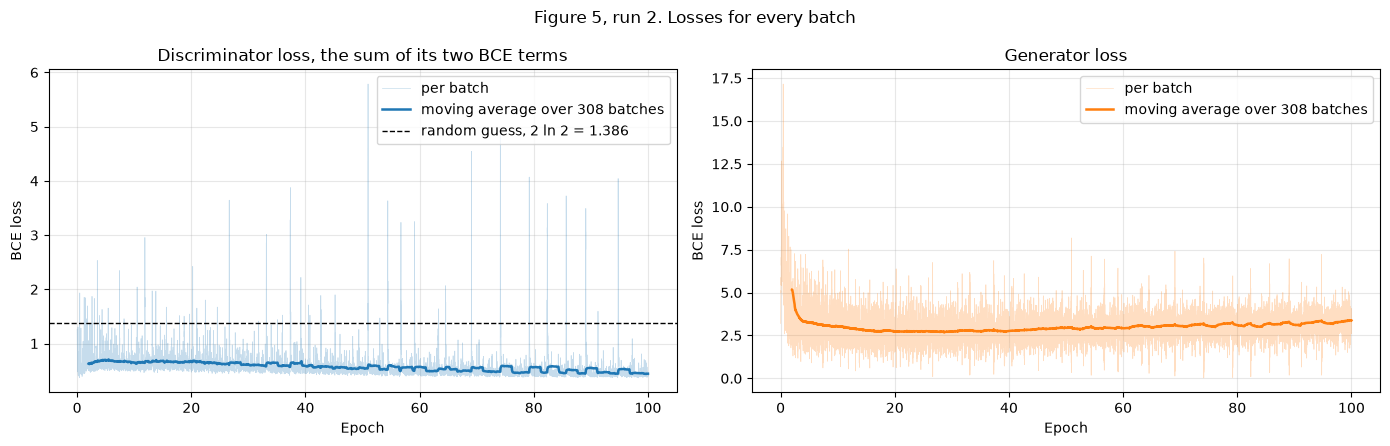

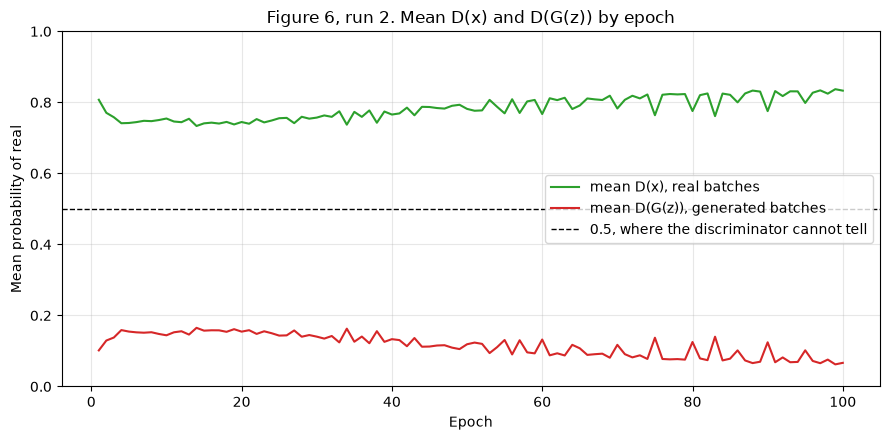

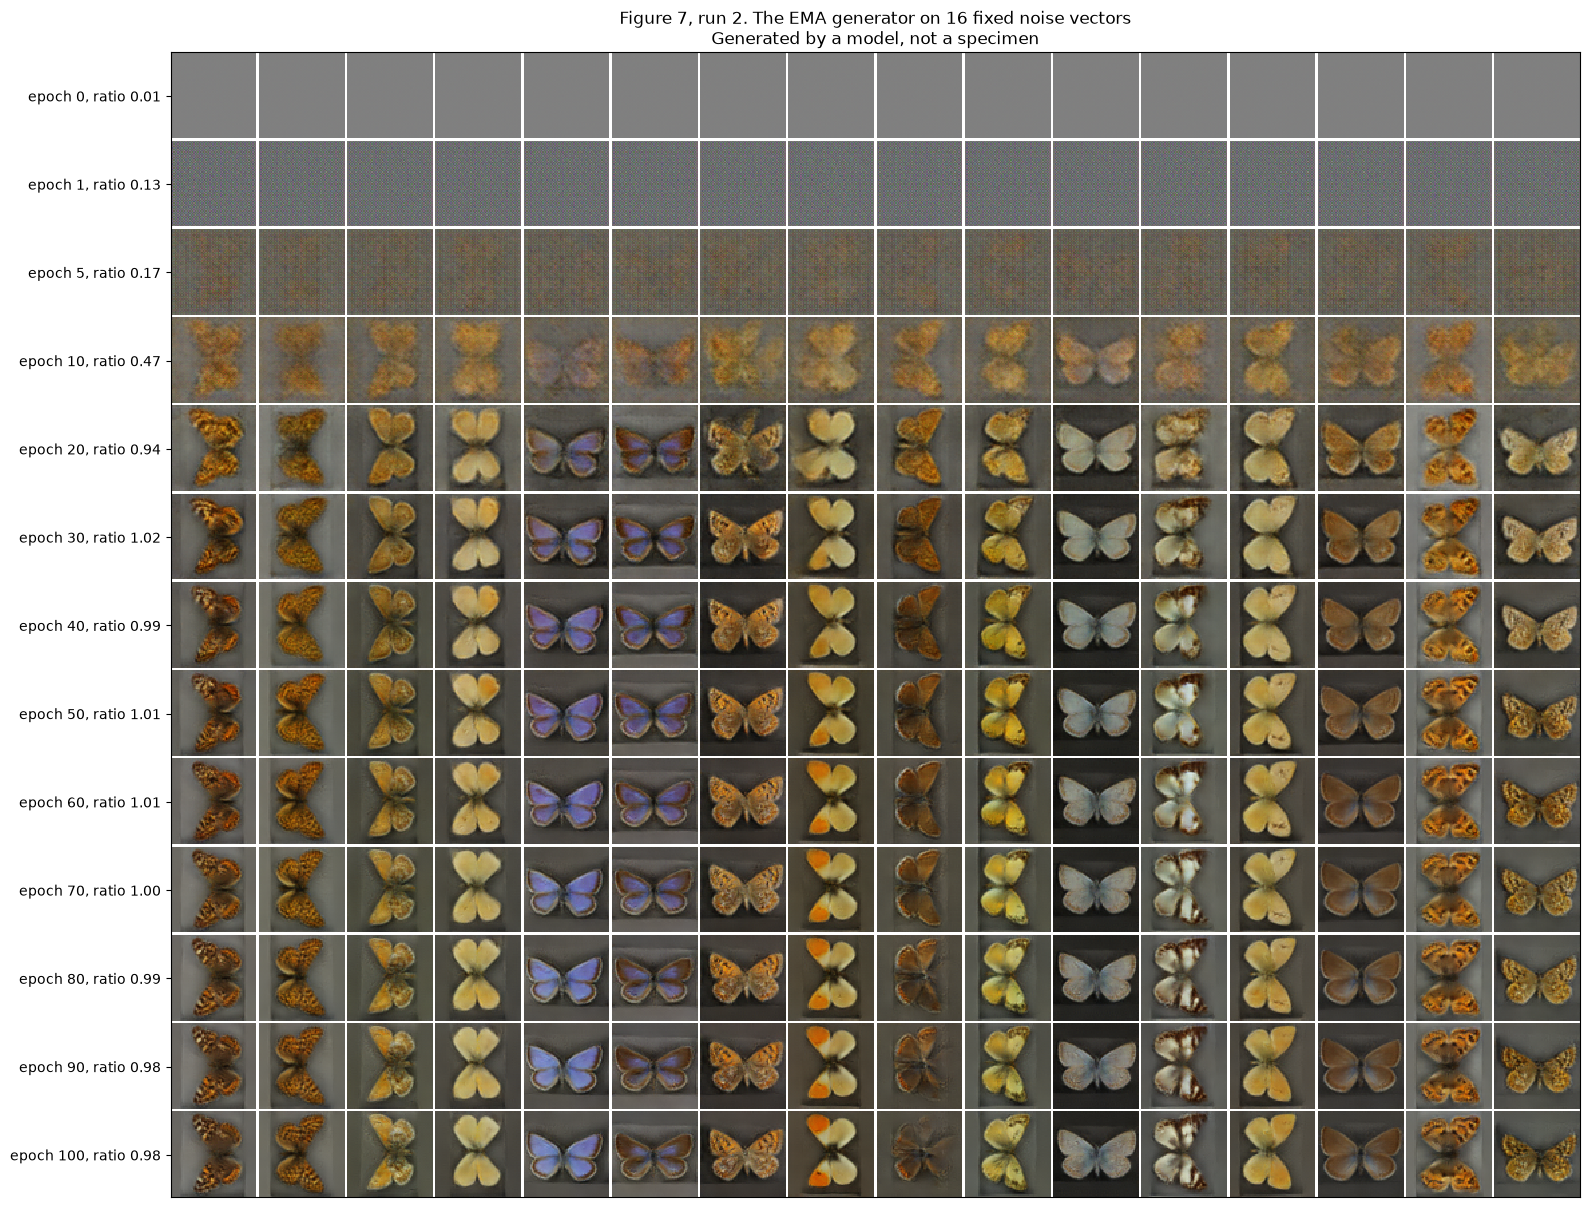

,flag,name,result,fired at epoch,window from epoch
0,F1,Discriminator domination,pass,,
1,F2,Discriminator failure,pass,,
2,F3,Unstable generator,fired,10,1
3,F4,Mode collapse,fired,10,10
4,F5,Non-finite loss,pass,,


F3, F4 fired in run 2, so run 3 is made.
Run 3 epoch   1: D loss 2.436, G loss 2.101, D(x) 0.444, D(G(z)) 0.695, 3.5 s for the epoch, 0.1 min so far, 6,584 MiB in use
Run 3 epoch   5: D loss 1.101, G loss 1.495, D(x) 0.562, D(G(z)) 0.330, 3.5 s for the epoch, 0.3 min so far, 6,584 MiB in use
Run 3 epoch  10: D loss 1.218, G loss 1.120, D(x) 0.506, D(G(z)) 0.389, 3.5 s for the epoch, 0.6 min so far, 6,584 MiB in use
Run 3 epoch  20: D loss 1.217, G loss 1.112, D(x) 0.509, D(G(z)) 0.389, 3.5 s for the epoch, 1.2 min so far, 6,584 MiB in use
Run 3 epoch  30: D loss 1.186, G loss 1.139, D(x) 0.520, D(G(z)) 0.380, 3.5 s for the epoch, 1.8 min so far, 6,584 MiB in use
Run 3 epoch  40: D loss 1.143, G loss 1.229, D(x) 0.535, D(G(z)) 0.363, 3.5 s for the epoch, 2.3 min so far, 6,584 MiB in use
Run 3 epoch  50: D loss 1.076, G loss 1.298, D(x) 0.557, D(G(z)) 0.344, 3.5 s for the epoch, 2.9 min so far, 6,584 MiB in use
Run 3 epoch  60: D loss 1.029, G loss 1.374, D(x) 0.575, D(G(z)) 0.325, 3.5 s

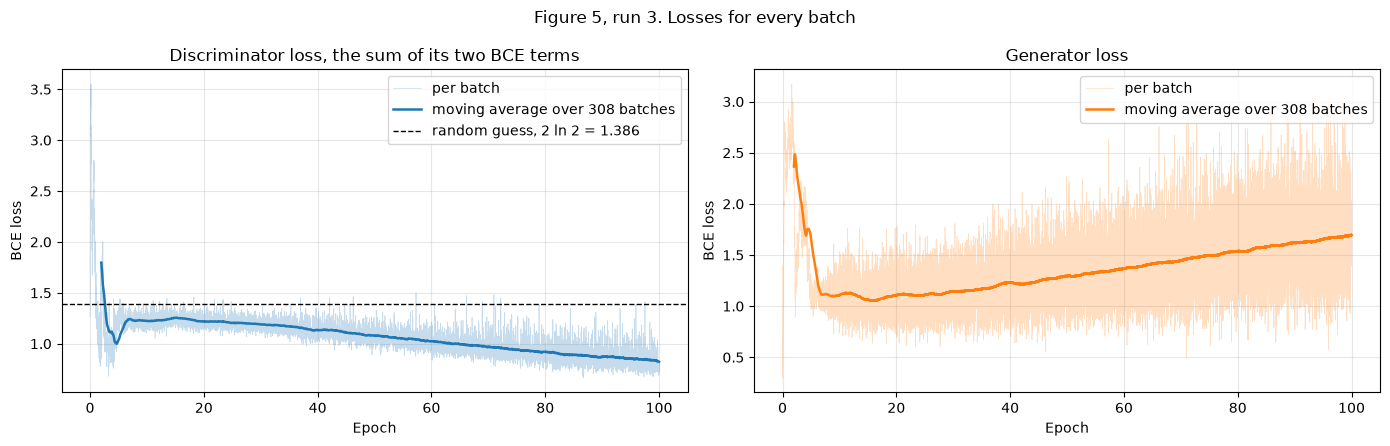

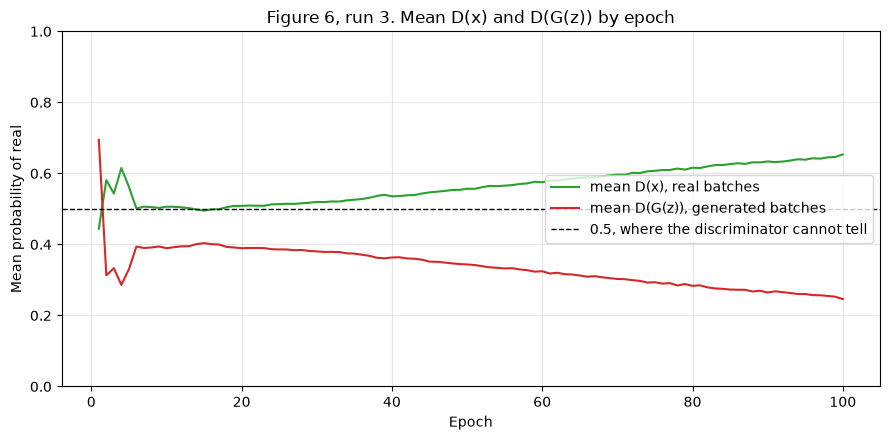

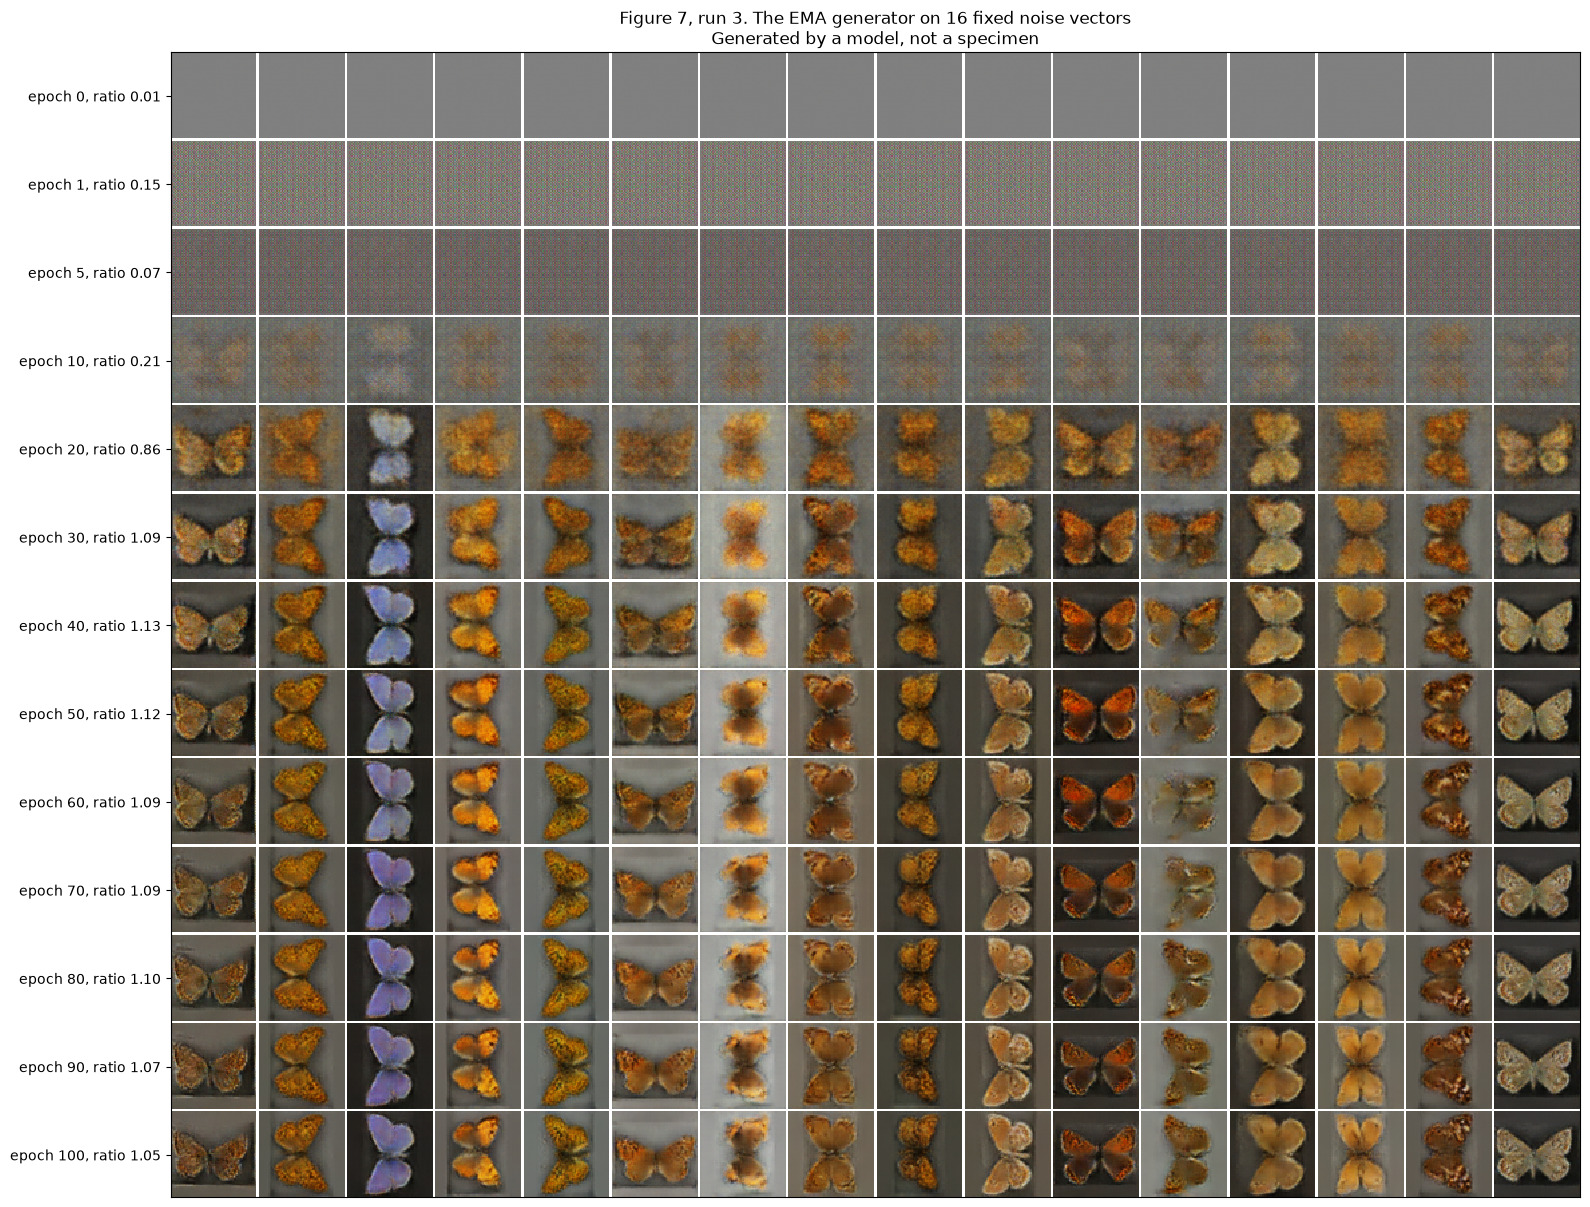

,flag,name,result,fired at epoch,window from epoch
0,F1,Discriminator domination,pass,,
1,F2,Discriminator failure,pass,,
2,F3,Unstable generator,pass,,
3,F4,Mode collapse,fired,10,10
4,F5,Non-finite loss,pass,,


F4 fired in run 3, and there is no fourth run.


In [25]:
following, reason = next_run(flags[1], 1)
print(f"{reason}.")
while following is not None:
    k = following
    runs[k] = train_run(
        train_u8,
        run_settings(RUN1, k, LR_D_TTUR),
        fixed_z,
        f4_reference,
        device,
        on_rig,
        Path(f"outputs/run{k}"),
        watchdog,
        used_mib,
    )
    print(describe_run(runs[k]))
    if runs[k]["stop"] and runs[k]["nonfinite_epoch"] is None:
        raise RuntimeError(
            f"the watchdog stopped run {k} ({runs[k]['stop']}), so no "
            "further run is made"
        )
    plot_losses(runs[k]["log"], f"Figure 5, run {k}. Losses for every batch")
    plt.show()
    plot_probabilities(
        runs[k]["log"], f"Figure 6, run {k}. Mean D(x) and D(G(z)) by epoch"
    )
    plt.show()
    plot_progression(
        runs[k]["checkpoints"],
        f"Figure 7, run {k}. The EMA generator on 16 fixed noise vectors\n"
        "Generated by a model, not a specimen",
    )
    plt.show()
    flags[k] = read_flags(
        runs[k]["log"], ratios_of(runs[k]), runs[k]["nonfinite_epoch"], LINES
    )
    display(flag_table(flags[k], FLAG_NAMES))
    following, reason = next_run(flags[k], k)
    print(f"{reason}.")

**What runs 2 and 3 show.**
- **Run 2, with spectral normalisation,** still let the discriminator lead: at epoch 100 mean D(x) was 0.833 and mean D(G(z)) 0.067. Its generator loss settled more than run 1's, with a spread of 0.653 over the last 10 epochs, at or under 1.0 in 89 of the 91 ten-epoch windows. But its first epoch averaged 6.318, so the spread over epochs 1 to 10 was 1.535 and F3 fired at epoch 10 again. F4 fired at the same checkpoint, with a ratio of 0.47, which was between 0.94 and 1.02 from epoch 20 on.
- **Run 3 kept spectral normalisation and slowed the discriminator to 0.00005,** the two time-scale update rule. It is the most even of the three runs. After its first epoch the discriminator's epoch-mean loss stayed under the random-guess line, easing to 0.812 by epoch 100, and mean D(x) and D(G(z)) parted slowly, to 0.653 and 0.246. Its highest single-batch generator loss was 3.17, and its ten-epoch spread never passed 0.576, so F3 stayed quiet.
- **But run 3 learnt slowly.** At epoch 10 the fixed noise still gave blurred, near-identical shapes, and F4's ratio was 0.21, so F4 fired there. From epoch 30 its ratio stayed between 1.05 and 1.13, and each vector gives a recognisable pinned specimen (Figure 7, run 3).
- F4 in run 3 ends the runs, as there is no fourth.

**The checkpoint rule applied.** The rule picks the checkpoint from the last run made, and its EMA generator and its discriminator are copied to `models/`. Then the training set and the untrained networks are freed from the GPU. Task 4 loads the checkpoint its first cell names.

In [26]:
last = max(runs)
saved = sorted(runs[last]["checkpoints"])
chosen = choose_checkpoint(flags[last], saved)
fired = [key for key, found in flags[last].items() if found]
print(
    f"The final model comes from run {last}, the last run made. Flags fired "
    f"in it: {', '.join(fired) if fired else 'none'}."
)
if chosen is None:
    raise RuntimeError(
        f"run {last} has no checkpoint the rule can pick, so the run failed"
    )
print(
    f"The checkpoint rule picks the EMA generator at epoch {chosen} of run "
    f"{last}, the {'last epoch' if not fired else 'fallback checkpoint'}."
)
if "F2" in fired:
    print("F2 fired, so this model stands as a failed run's fallback.")
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
files = runs[last]["checkpoints"][chosen]["files"]
for name in ("generator_ema", "discriminator"):
    target_path = MODELS / f"{name}.pt"
    shutil.copyfile(files[name], target_path)
    print(
        f"{target_path}: {target_path.stat().st_size / 2**20:.1f} MiB, "
        f"SHA-256 {bws.file_sha256(target_path)}, from {files[name]}"
    )
chosen_d = runs[last]["log"][chosen - 1].mean(axis=0)
print(
    f"Epoch {chosen}'s means: D loss {chosen_d[0]:.3f}, G loss "
    f"{chosen_d[1]:.3f}, D(x) {chosen_d[2]:.3f}, D(G(z)) {chosen_d[3]:.3f}"
)
# Task 4 reloads the chosen networks from models/, so I free the training
# set and the untrained networks from the GPU here.
del train_u8, generator, discriminator, real_64, fake_64
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()
    print(
        "GPU memory held by PyTorch after freeing the training run: "
        f"{torch.cuda.memory_allocated() / 2**20:.0f} MiB allocated, "
        f"{torch.cuda.memory_reserved() / 2**20:.0f} MiB reserved"
    )

The final model comes from run 3, the last run made. Flags fired in it: F4.
The checkpoint rule picks the EMA generator at epoch 5 of run 3, the fallback checkpoint.
models/generator_ema.pt: 13.7 MiB, SHA-256 e9238503a204a20db670406cb8eecff4638c861c68f8ec15cb0afcaff44df6d7, from outputs/run3/epoch_005_generator_ema.pt
models/discriminator.pt: 10.6 MiB, SHA-256 bad22c428521b5cf88dc9b18d07439600494e08b1d00223c9131077fecc86dd2, from outputs/run3/epoch_005_discriminator.pt
Epoch 5's means: D loss 1.101, G loss 1.495, D(x) 0.562, D(G(z)) 0.330
GPU memory held by PyTorch after freeing the training run: 32 MiB allocated, 74 MiB reserved


**The model the rule chose, and the failure it reports.** Applied as written, the rule picks run 3's EMA generator at epoch 5. F4 fired at epoch 10, and epoch 5 is the last checkpoint from epoch 5 on before that. At epoch 5 run 3's generator still makes a fine noise texture, with a diversity ratio of 0.07, lower than the 0.21 that fired F4 (Figure 7, run 3). So the chosen model is close to untrained, and this result stands in the notebook as a failure of the rule.
- In all three runs a flag fired at its first chance, at epoch 10. F3's window took in the first epoch's start-up spike, and F4 read generators that had not yet learnt to vary, where it was written to catch ones that had collapsed.
- Every run's later checkpoints show varied, recognisable specimens, with ratios near 1.0. The rule was fixed before training, and I have not changed it after seeing these results.
- The 32 MiB still allocated after freeing is the workspace cuBLAS keeps for the deterministic setting. No tensor is left on the GPU.

**The rule as written, a minimal correction, and the model I evaluate.** The rule above picks run 3's EMA generator at epoch 5. The next cell shows what that model makes, on the first 16 of the noise vectors Task 4 uses. It then applies one correction to the rule and changes nothing else: no flag window takes in epoch 1, the start-up transient. It prints each run's flags as written and as corrected, then run 1's ten-epoch spreads of the generator loss against F3's line, and F4's diversity ratios.

In [ ]:
def checkpoint_files(run, epoch, root="outputs"):
    """The EMA generator and the discriminator saved for run at epoch, as a
    new dict of paths."""
    folder = Path(root) / f"run{run}"
    return {
        name: folder / f"epoch_{epoch:03d}_{name}.pt"
        for name in ("generator_ema", "discriminator")
    }


def load_checkpoint(run, epoch, spectral, device, root="outputs"):
    """The EMA generator and the discriminator saved for run at epoch, in
    new networks on device in evaluation mode, as (generator,
    discriminator). spectral says whether the run's discriminator was
    spectrally normalised."""
    files = checkpoint_files(run, epoch, root)
    generator, discriminator = make_models(0, spectral=spectral)
    for net, name in (
        (generator, "generator_ema"),
        (discriminator, "discriminator"),
    ):
        state = torch.load(files[name], map_location="cpu", weights_only=True)
        net.load_state_dict(state)
    return generator.to(device).eval(), discriminator.to(device).eval()


def trailing_spreads(log, window=10):
    """The standard deviation of the per-batch generator loss over each run
    of window epochs, keyed by the epoch that ends it, from epoch window on,
    as a new dict. F3 reads these against its line."""
    g = log[:, :, 1]
    spreads = {}
    for epoch in range(window, len(log) + 1):
        start = epoch - window
        spreads[epoch] = float(g[start:epoch].std())
    return spreads


def flag_summary(flags):
    """Each flag as "pass" or where it fired, in a new dict keyed F1 to F5."""
    return {
        key: (
            f"fired at epoch {found[0]}, window from {found[1]}"
            if found
            else "pass"
        )
        for key, found in flags.items()
    }


# The rule as written picked this checkpoint (task3-choose above). Its
# samples on the first 16 of Task 4's noise vectors show what it makes.
picked_g, _ = load_checkpoint(
    last, chosen, runs[last]["settings"]["spectral"], device
)
picked = render(picked_g, noise_batch(16, SEED_SAMPLES, NZ), device)
del picked_g
plt.figure(figsize=(10, 3.2))
plt.imshow(tile(picked, cols=8))
plt.title(
    f"The rule's pick: run {last}'s EMA generator at epoch {chosen} on the "
    f"first 16 sample noise vectors (seed {SEED_SAMPLES})\n"
    "Generated by a model, not a specimen"
)
plt.axis("off")
plt.show()
print(
    f"Run {last} at epoch {chosen}: diversity ratio "
    f"{runs[last]['checkpoints'][chosen]['ratio']:.2f} on the fixed noise"
)

# The one-line correction: no flag window takes in epoch 1, the start-up
# transient. Everything else in the rule stays as written.
corrected = {
    k: read_flags(
        runs[k]["log"],
        ratios_of(runs[k]),
        runs[k]["nonfinite_epoch"],
        LINES,
        first_epoch=2,
    )
    for k in runs
}
columns = {}
for k in runs:
    columns[f"run {k} as written"] = flag_summary(flags[k])
    columns[f"run {k}, windows from epoch 2"] = flag_summary(corrected[k])
with pd.option_context("display.max_colwidth", 40, "display.width", 200):
    display(pd.DataFrame(columns))
for k in runs:
    print(f"With windows from epoch 2: {next_run(corrected[k], k)[1]}.")
again = choose_checkpoint(corrected[last], saved)
print(
    f"So the corrected rule still ends on run {last} and picks epoch "
    f"{again}."
)

spreads = trailing_spreads(runs[1]["log"])
on_or_under = sum(s <= LINES["F3"] for s in spreads.values())
late = {e: s for e, s in spreads.items() if e > 10}
print(
    f"Run 1's ten-epoch generator loss spreads: {on_or_under} of "
    f"{len(spreads)} windows at or under F3's line of {LINES['F3']}. "
    f"Leaving out every window that takes in epoch 1, "
    f"{sum(s > LINES['F3'] for s in late.values())} of {len(late)} are "
    f"above it. The last, epochs {max(spreads) - 9} to {max(spreads)}, is "
    f"{spreads[max(spreads)]:.3f}"
)
late_low = min(
    r for k in runs for e, r in ratios_of(runs[k]).items() if e >= 20
)
print(
    "F4's diversity ratio at epoch 10, the first checkpoint it reads: "
    + ", ".join(
        f"run {k} {runs[k]['checkpoints'][10]['ratio']:.2f}" for k in runs
    )
    + f"; from epoch 20 on, the lowest in any run is {late_low:.2f}"
)

**What the correction shows, and the model I evaluate.**
- **The rule as written** picks run 3's EMA generator at epoch 5. Its samples above are fine noise textures with no specimen in them, and its diversity ratio of 0.07 is lower than the 0.21 that fired F4. Applied as written, the rule chooses a model close to untrained.
- **The defect.** F3 and F4 were checked from the start of training with no warm-up. A normal start-up transient, the first epoch's generator loss, read as instability, and generators that had not yet learnt to vary read as collapsed. The fallback then pointed backwards in training, to a checkpoint before either window began.
- **The minimal correction** starts every flag window at epoch 2 and changes nothing else. It does not clear run 1. Run 1's generator loss spread sits near F3's line of 1.0 all through training: 46 of its 91 ten-epoch windows are at or under the line, and the last, epochs 91 to 100, is 1.032. F4 still fires for runs 2 and 3 at epoch 10, because its first check is at epoch 10, so the corrected rule still ends on run 3 at epoch 5.
- **A finding about the stability indicators.** F3's line and F4's check at epoch 10 are miscalibrated for this model. F3's line of 1.0 came from my coursework's check on a different GAN, and this generator's loss spreads that much while its samples keep improving (Figure 7). F4 at epoch 10 reads generators still learning to vary, and from epoch 20 on every run's ratio sits near 1.0. I report this as a finding, and I do not repair the rule here.
- **The model I evaluate.** Run 1's EMA generator at epoch 100. It is the plain recipe set before training, from the first run made, at its last epoch, so it takes the least choosing after seeing the outputs. I chose it after seeing the outputs of all three runs, so the choice is not blind. Runs 2 and 3 stay above as evidence on stability.

[PADDY] **PROVISIONAL, pending your ruling.** Task 4's first code cell names this checkpoint in one variable, so another ruling reruns Task 4 in minutes.

## Task 4: Generate and Evaluate Outputs

## Task 5: Write a Short Notebook Summary